# <font color='#BFD72F' size=6>**Preprocessing: from diagnosis to a leak-safe recipe**</font>

Diagnosis of `train.csv` / `test.csv` (sections 1–4), the rules and evidence behind `src/` and `config.yaml` (sections 5–8), the encoder × scaler and model choices (sections 9–10), and the data additions and imputers tested in cross-validation (sections 11–12). The notebook imports the pipeline's own functions, so it always runs the same code as `python main.py`.

<div class="alert alert-block alert-info">

## Table of Contents <a class="anchor" id="toc"></a>
- [0. Imports and configuration](#imports)
- [1. Data import](#data-import)
- [2. Cleaning and missing values](#cleaning)
- [3. Date validation](#dates)
- [4. Duplicates](#duplicates)
- [5. From diagnosis to pipeline rules](#rules)
- [6. Missingness mechanism of the remaining gaps](#mechanism)
- [7. Features, targets and the locked test set](#split)
- [8. The recipe: `build_preprocessor()`](#recipe)
- [9. Choosing the encoder × scaler pair](#encoder-scaler)
- [10. Recipe + model = one Pipeline](#pipeline)
- [11. Data additions: consistency rules, new features, customer table, rare categories](#additions)
- [12. Alternative imputers](#imputers)
- [13. From this notebook to the pipeline](#to-pipeline)
</div>

# <font color='#BFD72F' size=6>**0. Imports and configuration**</font> <a class="anchor" id="imports"></a>

[Back to TOC](#toc)

In [1]:
import os
import sys
from pathlib import Path

# run from the project root, whether Jupyter was started there or in notebooks/
ROOT = Path.cwd() if (Path.cwd() / "config.yaml").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from scipy import stats

from src.data import (
    load_data, report_placeholders, validate_schema, validate_customer_ids, standardize_columns, standardize_dtypes,
)
from src.cleaning import flag_invalid_values, apply_consistency_rules, prepare_table, drop_training_rows, fill_from_customer_history
from src.preprocessing import split_dev_test, check_feature_lists, build_preprocessor, task_preprocessing_config
from src.evaluate import (
    select_scoring, temporal_folds, cross_validate_pipeline, compare_encoders_scalers,
    compare_preprocessing_variants, paired_comparison,
)
from src.pipeline import build_pipeline, prepare_task_data, predict_new_records
from src.tasks import TASKS
import classification.preprocessing as classification_prep
import regression.preprocessing as regression_prep
import classification.model as classification_model
import regression.model as regression_model

# every rule and choice (column lists, placeholder value, seeds, ...) comes from config.yaml
with open("config.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)
data_cfg, diag_cfg, prep_cfg = config["data"], config["diagnostics"], config["preprocessing"]

# each task's metrics (config.yaml -> <task>.metrics) as sklearn scoring strings
SCORING = {task: select_scoring(TASKS[task].evaluate.SCORING, config[task]["metrics"]) for task in TASKS}

# <font color='#BFD72F' size=6>**1. Data import**</font> <a class="anchor" id="data-import"></a>

[Back to TOC](#toc)

In [2]:
# placeholder tokens ("?", "N/A", blank, ...) become NaN on load -- see section 2.2
tokens = diag_cfg["placeholder_tokens"]
train_raw = load_data(data_cfg["train_path"], tokens)
test_raw = load_data(data_cfg["test_path"], tokens)
clientes_raw = load_data(data_cfg["clientes_path"], tokens)

### 1.1 Column-name standardisation

The CSV files are stored as `train_raw`, `test_raw`, and `clientes_raw` for traceability. Standardised copies with lowercase English `snake_case` names become the working datasets used by every subsequent cleaning step. `standardize_columns()` (in `src/data.py`) uses the explicit names in `config.yaml` → `diagnostics.column_renames` and a generic snake_case rule for the rest, and raises an error if two columns end up with the same name.

In [3]:
train = standardize_columns(train_raw, diag_cfg["column_renames"])
test = standardize_columns(test_raw, diag_cfg["column_renames"])
clientes = standardize_columns(clientes_raw, diag_cfg["column_renames"])

column_changes = pd.DataFrame({
    "original": train_raw.columns,
    "standardized": train.columns,
})

display(column_changes.query("original != standardized"))
print("All standardized schemas have unique column names.")


,original,standardized
0,Total a Pagar,total_payable
1,Total Bruto,gross_total
2,Total Liquido,net_total
3,Total Imp_,total_tax
4,Total Portes,shipping_cost
5,Total Desc_ Global,global_discount_total
6,Total Desc_ Linha,line_discount_total
7,Custo,cost
8,N_ Detalhes,line_item_count
38,ID,id


All standardized schemas have unique column names.


**Conclusion — section 1.** Three files loaded: train.csv (6,534 purchases, both targets), test.csv (986 purchases, no targets) and clientes.csv (1,143 customers). 10 columns are renamed (the 9 Portuguese names and `ID`), and every name is unique. All later steps use these names.

# <font color='#BFD72F' size=6>**2. Cleaning and missing values**</font> <a class="anchor" id="cleaning"></a>

[Back to TOC](#toc)

### 2.1 Almost-empty rows

Exploratory analysis found 65 rows where only `id`, `customer_id`, and the classification target are present. We reproduce that pattern using all remaining columns rather than a manually selected subset (`config.yaml` → `diagnostics.almost_empty_preserved_columns`). This cell only **diagnoses** them; they are removed from training in section 2.4.

In [4]:
preserved_columns = diag_cfg["almost_empty_preserved_columns"]
almost_empty_columns = [
    column for column in train.columns
    if column not in preserved_columns
]
missing_pattern = train[almost_empty_columns].isna().all(axis=1)

affected = train.loc[missing_pattern, ["id", "customer_id"]].copy()

# Check whether each customer_id exists in clientes.
customer_id_col = "customer_id"

affected["exists_in_clientes"] = affected["customer_id"].isin(
    clientes[customer_id_col]
)

# Display the results
print("Affected rows:", len(affected))
print("\nCross-check results:")
print(affected["exists_in_clientes"].value_counts(dropna=False))

print("\nCustomers not found in clientes:")
print(
    affected.loc[~affected["exists_in_clientes"]]
    .sort_values("customer_id")
)


Affected rows: 65

Cross-check results:
exists_in_clientes
True    65
Name: count, dtype: int64

Customers not found in clientes:
Empty DataFrame
Columns: [id, customer_id, exists_in_clientes]
Index: []


### 2.2 Placeholders and invalid numeric values

**Placeholder tokens.** `report_placeholders()` reads each raw file as plain text, before pandas converts anything, and counts every token in `config.yaml` → `diagnostics.placeholder_tokens` (blank, `-`, `?`, `N/A`, `null`, `unknown`, …). It also counts the numeric placeholder `1,000,000,000`:

In [5]:
placeholder_report = pd.concat(
    {name: report_placeholders(data_cfg[f"{name}_path"], diag_cfg) for name in ["train", "test", "clientes"]},
    names=["file"],
).reset_index(level=0)
display(placeholder_report.groupby(["file", "placeholder", "treatment"])["count"].agg(["sum", "count"])
        .rename(columns={"sum": "occurrences", "count": "columns"}))
display(placeholder_report.query("file == 'train'").sort_values("count", ascending=False).head(10))

occurrences  \
file     placeholder   treatment                                                 
clientes ''            NaN on load (load_data)                            3385   
test     ''            NaN on load (load_data)                             489   
         1,000,000,000 NaN in clean_dataset (flag_invalid_values)            4   
train    ''            NaN on load (load_data)                           12927   
         1,000,000,000 NaN in clean_dataset (flag_invalid_values)           31   

                                                                   columns  
file     placeholder   treatment                                            
clientes ''            NaN on load (load_data)                           9  
test     ''            NaN on load (load_data)                          12  
         1,000,000,000 NaN in clean_dataset (flag_invalid_values)        2  
train    ''            NaN on load (load_data)                          37  
         1,000,000,000 NaN in clean_dataset (flag_invalid_values)        2

,file,column,placeholder,count,treatment
10,train,spend_next_90d,'',3109,NaN on load (load_data)
21,train,prior_std_gap_days,'',1478,NaN on load (load_data)
20,train,prior_mean_gap_days,'',1308,NaN on load (load_data)
17,train,prior_std_purchase_value,'',1113,NaN on load (load_data)
15,train,prior_mean_purchase_value,'',862,NaN on load (load_data)
11,train,days_since_previous_purchase,'',861,NaN on load (load_data)
18,train,prior_min_purchase_value,'',668,NaN on load (load_data)
19,train,prior_max_purchase_value,'',668,NaN on load (load_data)
34,train,transport_method,'',261,NaN on load (load_data)
29,train,spend_365d,'',260,NaN on load (load_data)


- **Blank cells are the only text placeholder in the three files** (12,927 in train.csv). No `?`, `N/A`, `-` or `unknown` appears. `load_data()` still turns every listed token into `NaN`, so a new file that uses `?` can't make a numeric column load as text.
- **The numeric placeholder `1,000,000,000`** appears 31 times in train.csv and 4 times in test.csv, always in `prior_mean_purchase_value` and `spend_365d`. It becomes `NaN` in `clean_dataset()` and is then recovered from identities (5.1).
- **Negative amounts, counts and time intervals** are impossible. They become missing values too (`config.yaml` → `diagnostics.non_negative_columns`, `placeholder_values`, `placeholder_columns`). Section 5.1 then recovers most of them exactly from identities between columns. No rows are removed.

In [6]:
non_negative_columns = diag_cfg["non_negative_columns"]
placeholder_columns = diag_cfg["placeholder_columns"]
placeholder_values = diag_cfg["placeholder_values"]

invalid_value_report = []
for dataset_name, df in {"train": train, "test": test}.items():
    for column in non_negative_columns:
        count = int(df[column].lt(0).sum())
        if count:
            invalid_value_report.append([dataset_name, column, "negative", count])

    for column in placeholder_columns:
        count = int(df[column].isin(placeholder_values).sum())
        if count:
            invalid_value_report.append([dataset_name, column, "placeholder", count])

invalid_value_report = pd.DataFrame(
    invalid_value_report, columns=["dataset", "column", "issue", "count"]
)
display(invalid_value_report)


,dataset,column,issue,count
0,train,days_since_previous_purchase,negative,16
1,train,prior_mean_purchase_value,negative,16
2,train,prior_mean_gap_days,negative,16
3,train,spend_365d,negative,15
4,train,prior_mean_purchase_value,placeholder,16
5,train,spend_365d,placeholder,15
6,test,days_since_previous_purchase,negative,2
7,test,prior_mean_purchase_value,negative,2
8,test,prior_mean_gap_days,negative,2
9,test,spend_365d,negative,2


In [7]:
train_clean, test_clean = train.copy(), test.copy()
flag_invalid_values(train_clean, diag_cfg)      # in place -- the same function clean_dataset() uses
flag_invalid_values(test_clean, diag_cfg)

for name, df in {"train": train_clean, "test": test_clean}.items():
    negatives_left = int(df[non_negative_columns].lt(0).sum().sum())
    placeholders_left = int(df[placeholder_columns].isin(placeholder_values).sum().sum())
    print(f"{name}: {negatives_left} negative values and {placeholders_left} placeholders left; {len(df)} rows (none removed)")

train: 0 negative values and 0 placeholders left; 6534 rows (none removed)
test: 0 negative values and 0 placeholders left; 986 rows (none removed)


### 2.3 Categorical text values

We compare categories before and after trimming whitespace and standardising case. No case or spacing variants are found, so the original category labels are kept.


In [8]:
categorical_columns = prep_cfg["categorical_features"]

category_text_report = []
for column in categorical_columns:
    values = pd.concat([train_clean[column], test_clean[column]]).dropna().astype(str)
    normalized = values.str.strip().str.casefold()
    category_text_report.append({
        "column": column,
        "values_with_whitespace": int(values.ne(values.str.strip()).sum()),
        "case_or_spacing_variants": values.nunique() - normalized.nunique(),
    })

category_text_report = pd.DataFrame(category_text_report)
display(category_text_report)
assert category_text_report[["values_with_whitespace", "case_or_spacing_variants"]].eq(0).all().all()


,column,values_with_whitespace,case_or_spacing_variants
0,payment_type,0,0
1,salesperson,0,0
2,commercial_zone,0,0
3,transport_method,0,0
4,warehouse,0,0
5,document_series,0,0


### 2.4 Training-only row removal

`drop_training_rows()` removes the 65 almost-empty rows found in 2.1, plus exact duplicates (ignoring `id`) and repeated ids. It runs on the **labelled training file only**: every test.csv id needs a prediction, so test rows are never removed.

In [9]:
train_clean, row_report = drop_training_rows(train_clean, diag_cfg, data_cfg["id_column"])
display(row_report)
print("Training rows after removal:", len(train_clean), "| test rows:", len(test_clean), "(test.csv is never filtered)")

,rule,rows_removed
0,almost-empty rows,65
1,exact duplicates (ignoring id),0
2,repeated ids,0


Training rows after removal: 6469 | test rows: 986 (test.csv is never filtered)


### 2.5 Data-type standardisation

Counts and identifiers use compact nullable integer types, category labels use `category`, and the binary target uses `Int8`. Monetary values and calculated statistics remain `float64` so that decimals are preserved. The rules live in `config.yaml` → `dtypes` and are also applied by `prepare_table()`.

In [10]:
train_memory_before = train_clean.memory_usage(deep=True).sum()
test_memory_before = test_clean.memory_usage(deep=True).sum()
train_types_before = train_clean.dtypes.astype(str)
test_types_before = test_clean.dtypes.astype(str)

train_clean = standardize_dtypes(train_clean, config["dtypes"])
test_clean = standardize_dtypes(test_clean, config["dtypes"])

type_changes = pd.DataFrame({
    "train_before": train_types_before,
    "train_after": train_clean.dtypes.astype(str),
    "test_before": test_types_before,
    "test_after": test_clean.dtypes.astype(str),
})
changed = (
    type_changes["train_before"].ne(type_changes["train_after"])
    | type_changes["test_before"].ne(type_changes["test_after"])
)
display(type_changes.loc[changed])
print(f"Train memory: {train_memory_before / 1024**2:.2f} MB -> {train_clean.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
print(f"Test memory: {test_memory_before / 1024**2:.2f} MB -> {test_clean.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

,train_before,train_after,test_before,test_after
commercial_zone,str,category,str,category
customer_id,int64,Int32,int64,Int32
customer_tenure_days,float64,Int16,float64,Int16
document_series,str,category,str,category
id,int64,Int32,int64,Int32
invoice_count_current_purchase,float64,Int16,float64,Int16
line_item_count,float64,Int16,float64,Int16
payment_type,str,category,str,category
prior_purchase_count,float64,Int16,float64,Int16
purchase_count_180d,float64,Int16,float64,Int16


Train memory: 4.64 MB -> 1.77 MB
Test memory: 0.68 MB -> 0.25 MB


### 2.6 Regression-target missingness

`spend_next_90d` is only defined for customers who come back, so it is missing for every non-repeater. That is structural and expected. The question is the repeaters whose spend is missing:

In [11]:
# Create a categorical variable indicating whether the regression target is missing
spend_status = train_clean["spend_next_90d"].isna().map({
    True: "Missing",
    False: "Observed"
})

# Summarise missingness by the classification target
# Rows = repeat_purchase_90d; columns = missingness status
missingness_counts = pd.crosstab(
    train_clean["repeat_purchase_90d"],
    spend_status
)

# Calculate row percentages to compare missingness rates within each class
missingness_percentages = pd.crosstab(
    train_clean["repeat_purchase_90d"],
    spend_status,
    normalize="index"
).mul(100).round(2)

print("Counts:")
print(missingness_counts)

print("\nPercentages within each repeat_purchase_90d class:")
print(missingness_percentages)

Counts:
spend_next_90d       Missing  Observed
repeat_purchase_90d                   
0                       2848         0
1                        196      3425

Percentages within each repeat_purchase_90d class:
spend_next_90d       Missing  Observed
repeat_purchase_90d                   
0                     100.00      0.00
1                       5.41     94.59


Is *being missing* related to anything? The same tests as section 6 (Mann-Whitney for numeric features, χ² for categorical ones with categories under 30 rows grouped as `rare`, Bonferroni threshold), restricted to repeat purchasers:

In [12]:
repeaters = train_clean.loc[train_clean["repeat_purchase_90d"].eq(1)]
spend_missing = repeaters["spend_next_90d"].isna()

rows = []
for feature in prep_cfg["numeric_features"]:
    missing_values = repeaters.loc[spend_missing, feature].dropna()
    observed_values = repeaters.loc[~spend_missing, feature].dropna()
    rows.append({"feature": feature, "test": "Mann-Whitney",
                 "median_missing": missing_values.median(), "median_observed": observed_values.median(),
                 "p_value": stats.mannwhitneyu(missing_values, observed_values).pvalue})
for feature in prep_cfg["categorical_features"]:
    values = repeaters[feature].astype("object").fillna("missing")
    values = values.where(values.map(values.value_counts()).ge(30), "rare")
    rows.append({"feature": feature, "test": "chi-squared",
                 "p_value": stats.chi2_contingency(pd.crosstab(spend_missing, values))[1]})

target_missing_tests = pd.DataFrame(rows).sort_values("p_value").reset_index(drop=True)
threshold = 0.05 / len(target_missing_tests)
target_missing_tests["related"] = target_missing_tests["p_value"] < threshold
print(f"Repeat purchasers: {len(repeaters)}, spend missing: {int(spend_missing.sum())} ({100 * spend_missing.mean():.1f}%)")
print(f"{int(target_missing_tests['related'].sum())} of {len(target_missing_tests)} features are related to the missing spend "
      f"(Bonferroni threshold {threshold:.4f})")
display(target_missing_tests.head(10).round(4))

Repeat purchasers: 3621, spend missing: 196 (5.4%)
13 of 32 features are related to the missing spend (Bonferroni threshold 0.0016)


,feature,test,median_missing,median_observed,p_value,related
0,transport_method,chi-squared,NaN,NaN,0.0000,True
1,salesperson,chi-squared,NaN,NaN,0.0000,True
2,purchase_count_365d,Mann-Whitney,3.00,5.000,0.0000,True
3,purchase_count_180d,Mann-Whitney,2.00,3.000,0.0000,True
4,spend_365d,Mann-Whitney,1972.77,4644.405,0.0000,True
5,spend_180d,Mann-Whitney,1039.70,2166.490,0.0000,True
6,document_series,chi-squared,NaN,NaN,0.0001,True
7,prior_purchase_count,Mann-Whitney,8.50,17.000,0.0001,True
8,commercial_zone,chi-squared,NaN,NaN,0.0002,True
9,shipping_cost,Mann-Whitney,0.00,0.000,0.0002,True


purchase_date,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
repeat_purchases,179.0,216.0,424.0,385.0,337.0,398.0,429.0,302.0,446.0,456.0,49.0
spend_missing_%,16.8,4.6,3.8,4.9,1.8,1.3,2.3,2.3,3.6,11.6,49.0


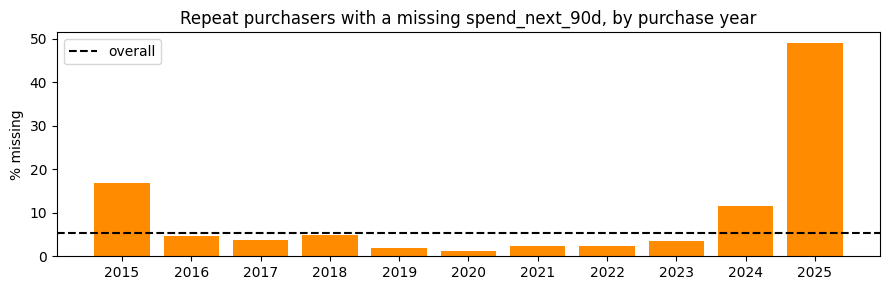

In [13]:
purchase_year = pd.to_datetime(repeaters["purchase_date"]).dt.year
by_year = pd.DataFrame({
    "repeat_purchases": purchase_year.value_counts().sort_index(),
    "spend_missing_%": spend_missing.groupby(purchase_year).mean().mul(100).round(1),
})
display(by_year.T)

fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(by_year.index.astype(str), by_year["spend_missing_%"], color="darkorange")
ax.axhline(100 * spend_missing.mean(), linestyle="--", color="black", label="overall")
ax.set_title("Repeat purchasers with a missing spend_next_90d, by purchase year")
ax.set_ylabel("% missing")
ax.legend()
plt.tight_layout()
plt.show()

**Verdict: not MCAR.**

- **Strongly time-dependent.** The missing share is concentrated at the two edges of the data: the first year (2015) and especially the last months (2024, and about half of the 2025 purchases). In the years in between it is low. This looks like the 90-day spend not being fully recorded at the edges of the data extract.
- **Related to the customer profile.** Rows with a missing spend come from customers with a shorter, lower-value history (fewer prior purchases, lower 180/365-day spend) and are associated with several categorical features.

**Decision:** a target is never imputed. Inventing a label would mean training on our own guesses. The regressor trains only on repeat purchasers with an observed spend (`config.yaml` → `regression.row_filter`), and its preprocessing is fitted on those rows only (`regression.select_training_rows()`, section 7).

**Consequence to keep in mind:** the regression training rows slightly over-represent longer, higher-value histories, and the most recent months (the locked test period) have fewer usable regression rows. The regressor's errors should be read with that in mind.

### 2.7 Missing-value treatment decision

- **Broad missingness:** exclude the 65 training rows with a simultaneous, broad predictor-missingness pattern from model fitting (section 2.4). There is no equivalent complete pattern in `test.csv`, and imputation would invent most of a purchase record. Keep the raw rows for audit only.
- **Predictor missingness:** first recover what the identities, the consistency rules and the column definitions allow (sections 5.1–5.3), then test the mechanism of what is left (section 6). Imputation and missingness indicators are fitted on each training fold only, inside the model `Pipeline`, to avoid leakage.
- **Targets:** never impute either target. The classification target is complete. The spend target is missing for 5.4% of repeaters, and not at random (section 2.6). Train the spend regressor only on repeat purchasers with an observed `spend_next_90d` value.
- **Clientes:** if the optional customer table is merged later, drop `customer_type` because it is entirely missing; handle the other customer fields within the same fold-safe preprocessing pipeline.

In [14]:
assert train_clean["repeat_purchase_90d"].notna().all()

eligible_repeaters = train_clean.loc[
    train_clean["repeat_purchase_90d"].eq(1)
].copy()
observed_regression_target = eligible_repeaters["spend_next_90d"].notna()

print("Classification training rows:", len(train_clean))
print("Regression training rows (observed spend only):", int(observed_regression_target.sum()))
print(
    "Repeat purchasers without an observed spend target:",
    int((~observed_regression_target).sum())
)

Classification training rows: 6469
Regression training rows (observed spend only): 3425
Repeat purchasers without an observed spend target: 196


### 2.8 Train/test feature compatibility

The two targets are expected to exist only in `train`. For every predictor shared by train and test, the data type must have the same broad meaning (numeric or text). Exact pandas dtypes may differ because missing numeric values are stored as floats.


In [15]:
target_columns = ["repeat_purchase_90d", "spend_next_90d"]
train_feature_columns = set(train_clean.columns) - set(target_columns)
test_feature_columns = set(test_clean.columns)

print("Features missing from test:", sorted(train_feature_columns - test_feature_columns))
print("Unexpected features in test:", sorted(test_feature_columns - train_feature_columns))

def dtype_family(series):
    return "numeric" if pd.api.types.is_numeric_dtype(series) else "text"

type_report = pd.DataFrame({
    "train_dtype": train_clean.dtypes,
    "test_dtype": test_clean.dtypes,
}).loc[sorted(train_feature_columns & test_feature_columns)]
type_report["train_family"] = [dtype_family(train_clean[column]) for column in type_report.index]
type_report["test_family"] = [dtype_family(test_clean[column]) for column in type_report.index]

display(type_report.query("train_dtype != test_dtype"))
assert train_feature_columns == test_feature_columns
assert type_report["train_family"].equals(type_report["test_family"])


Features missing from test: []
Unexpected features in test: []


,train_dtype,test_dtype,train_family,test_family
commercial_zone,category,category,text,text
document_series,category,category,text,text
payment_type,category,category,text,text
salesperson,category,category,text,text
transport_method,category,category,text,text
warehouse,category,category,text,text


### 2.9 Test categories unseen in training

Some valid test categories do not appear in training. They are not renamed: the later encoder must handle unknown categories safely.


In [16]:
unseen_category_report = []
for column in categorical_columns:
    train_categories = set(train_clean[column].dropna().astype(str))
    test_categories = set(test_clean[column].dropna().astype(str))
    unseen_in_train = sorted(test_categories - train_categories)
    unseen_category_report.append({
        "column": column,
        "test_categories_unseen_in_train": ", ".join(unseen_in_train) or "None",
    })

unseen_category_report = pd.DataFrame(unseen_category_report)
display(unseen_category_report.query("test_categories_unseen_in_train != 'None'"))


,column,test_categories_unseen_in_train
0,payment_type,"Maybe Tomorrow Payment 1, Maybe Tomorrow Payme..."
2,commercial_zone,"Decorative Dashboard Zone 1, Decorative Dashbo..."
3,transport_method,"Maybe Tomorrow Delivery 54, Maybe Tomorrow Del..."
4,warehouse,Final Excel Warehouse 2


### 2.10 Schema validation (expected types, valid ranges, allowed categories)

`validate_schema()` is the first step of `prepare_table()`, so every table goes through it: train.csv, test.csv and any new record. Its rules live in `config.yaml` → `schema`:
- **required columns:** an error if one is missing; extra columns are reported;
- **expected types:** numeric columns must be numeric (anything that can't be read as a number → `NaN`, counted), dates must parse, count columns must hold whole numbers;
- **valid ranges:** every non-negative column has min 0, plus explicit ranges (`purchase_date` from 2010 up to today, so a future date is caught, ≥ 1 line item and invoice, target 0/1, spend ≥ 0). Out-of-range values are counted here and turned into `NaN` by `clean_dataset()`;
- **allowed categories:** every label follows `"<fixed text> <number>"` (e.g. `Maybe Tomorrow Payment 12`). A label that doesn't match is not a category → `NaN`, counted. Labels that match but were never seen in training are allowed; the encoders handle them.

In [17]:
schema_reports = {}
for name, raw in {"train": train_raw, "test": test_raw}.items():
    validated, schema_reports[name] = validate_schema(
        standardize_columns(raw, diag_cfg["column_renames"]), config["schema"], diag_cfg["non_negative_columns"])
    assert len(validated) == len(raw)
schema_summary = pd.concat(schema_reports, names=["file"]).reset_index(level=0)
display(schema_summary.groupby(["file", "step"])["values"].sum().unstack("file").fillna(0).astype(int))
display(schema_summary.query("values > 0"))

file,test,train
step,,
schema: label not allowed -> NaN,0,0
schema: non-integer value,0,0
schema: outside valid range,8,63
schema: unparseable date,0,0


,file,step,column,values,rule
22,train,schema: outside valid range,days_since_previous_purchase,16,"[0, inf]"
26,train,schema: outside valid range,prior_mean_purchase_value,16,"[0, inf]"
30,train,schema: outside valid range,prior_mean_gap_days,16,"[0, inf]"
39,train,schema: outside valid range,spend_365d,15,"[0, inf]"
21,test,schema: outside valid range,days_since_previous_purchase,2,"[0, inf]"
25,test,schema: outside valid range,prior_mean_purchase_value,2,"[0, inf]"
29,test,schema: outside valid range,prior_mean_gap_days,2,"[0, inf]"
38,test,schema: outside valid range,spend_365d,2,"[0, inf]"


Both files have every required column with the expected type, every date parses, every count is a whole number, and **every category label is allowed**. The only out-of-range values are the 63 negatives in train.csv (8 in test.csv) already found in 2.2. They are counted here and become missing values in `clean_dataset()`.

**Conclusion — section 2.**
- **Almost-empty rows:** 65 training rows have nothing but ids and the label. They are removed from training only.
- **Placeholders:** the only text placeholder is the blank cell. The `1,000,000,000` placeholder (2 columns) and negative values (4 columns) become missing values, and section 5 recovers most of them.
- **Schema:** every required column, type, date and category label is valid (2.10). `validate_schema()` checks the same rules on every new table.
- **Category labels:** clean, with no case or spacing variants.
- **Spend target:** missing for all non-repeaters (structural), and *not at random* for 5.4% of repeaters, so it is never imputed.
- **Train vs test:** both share the same features with compatible types, but test.csv has categories never seen in training, so every encoder must handle unknown categories.

# <font color='#BFD72F' size=6>**3. Date validation**</font> <a class="anchor" id="dates"></a>

- 3.1 **Date validity:** Count missing and unparseable dates in both datasets. Avoid crashes when it contains no valid dates.
- 3.2 **Temporal coverage:** Report the minimum and maximum valid dates for each dataset, with consistent formatting.
- 3.3 **Train/test chronology:** Check whether the training period ends before the test period begins. Report inconsistencies as a warning.
- 3.4 **Temporal distribution:** Check whether dates are concentrated in particular periods and whether there are unexpected gaps, if the data is expected to cover a continuous timeline.

[Back to TOC](#toc)

In [18]:

def validate_purchase_dates(train, test):
    """Validate purchase dates and compare train/test time periods."""

    datasets = {"train": train.copy(), "test": test.copy()}
    date_col = "purchase_date"
    date_ranges = {}

    # Step 1: Check that both datasets contain the date column.
    for name, df in datasets.items():
        if date_col not in df.columns:
            raise KeyError(f"'{date_col}' is missing from {name}.")

    # Step 2: Parse dates and report invalid or missing values.
    for name, df in datasets.items():
        # Convert invalid date strings to NaT instead of raising errors.
        df[date_col] = pd.to_datetime(
            df[date_col],
            errors="coerce"
        )

        valid_dates = df[date_col].dropna()
        invalid_count = df[date_col].isna().sum()

        print(f"\n--- {name.upper()} DATE VALIDATION ---")
        print(f"Total observations: {len(df)}")
        print(f"Missing/unparseable dates: {invalid_count}")

        # Step 3: Calculate the date interval safely.
        if valid_dates.empty:
            print("No valid dates available.")
            date_ranges[name] = None
            continue

        earliest = valid_dates.min()
        latest = valid_dates.max()

        date_ranges[name] = (earliest, latest)

        print(f"Earliest date: {earliest}")
        print(f"Latest date:   {latest}")

        monthly_counts = valid_dates.dt.to_period("M").value_counts().sort_index()
        full_period = pd.period_range(
            earliest.to_period("M"), latest.to_period("M"), freq="M"
        )
        missing_months = full_period.difference(monthly_counts.index)
        print(f"Months without purchases: {len(missing_months)}")

    # Step 4: Compare the temporal coverage of both datasets.
    train_range = date_ranges["train"]
    test_range = date_ranges["test"]

    if train_range is None or test_range is None:
        print("\nCannot compare periods: at least one dataset has no valid dates.")
        return datasets["train"], datasets["test"]

    train_start, train_end = train_range
    test_start, test_end = test_range

    print("\n--- TRAIN/TEST CHRONOLOGY ---")

    if train_end < test_start:
        print("PASS: Training dates precede test dates.")
    elif test_end < train_start:
        print("WARNING: Test period precedes training period.")
    else:
        print("WARNING: Train/test date ranges overlap.")

        overlap_start = max(train_start, test_start)
        overlap_end = min(train_end, test_end)

        print(f"Overlapping interval: {overlap_start} to {overlap_end}")

    return datasets["train"], datasets["test"]


train_clean, test_clean = validate_purchase_dates(train_clean, test_clean)


--- TRAIN DATE VALIDATION ---
Total observations: 6469
Missing/unparseable dates: 0
Earliest date: 2015-07-11 00:00:00
Latest date:   2025-02-15 00:00:00
Months without purchases: 0

--- TEST DATE VALIDATION ---
Total observations: 986
Missing/unparseable dates: 0
Earliest date: 2025-05-24 00:00:00
Latest date:   2026-10-06 00:00:00
Months without purchases: 0

--- TRAIN/TEST CHRONOLOGY ---
PASS: Training dates precede test dates.


**Conclusion — section 3.** Every date parses, there are no months without purchases, and test.csv (2025-05 → 2026-10) starts after train.csv ends (2025-02). So the models must be validated on *later* purchases than they are trained on (section 7).

# <font color='#BFD72F' size=6>**4. Duplicates**</font> <a class="anchor" id="duplicates"></a>

- 4.1 Exact duplicate rows in each dataset, both on all columns and **ignoring `id`** (a unique `id` would otherwise hide every duplicate).
- 4.2 Repeated ids.
- 4.3 Test rows identical to a training row (shared columns except `id`), which would hint at leakage.
- 4.4 `customer_id` validation: present, a positive integer, known in clientes.csv, and a purchase history that never goes backwards for the same customer.

This section is **diagnostic only**. Training duplicates are removed by `drop_training_rows()` (section 2.4), and test rows are never removed, because every one of the 986 ids needs a prediction.

[Back to TOC](#toc)

In [19]:
def duplicate_diagnostics(train, test, id_column):
    """Counts duplicates in train and test and train/test overlaps. Removes nothing."""
    rows = []
    for name, df in {"train": train, "test": test}.items():
        non_id_columns = [c for c in df.columns if c != id_column]
        rows.append({
            "dataset": name,
            "rows": len(df),
            "exact duplicates (all columns)": int(df.duplicated().sum()),
            "duplicates ignoring id": int(df.duplicated(subset=non_id_columns).sum()),
            "repeated ids": int(df[id_column].duplicated().sum()),
        })

    shared = [c for c in train.columns if c in test.columns and c != id_column]
    train_hashes = set(pd.util.hash_pandas_object(train[shared], index=False))
    test_matches = int(pd.util.hash_pandas_object(test[shared], index=False).isin(train_hashes).sum())
    return pd.DataFrame(rows), test_matches

In [20]:
duplicate_table, test_rows_matching_train = duplicate_diagnostics(train_clean, test_clean, data_cfg["id_column"])
display(duplicate_table)
print("Test rows identical to a training row (shared columns except id):", test_rows_matching_train)

assert len(test_clean) == len(test_raw) == 986, "test.csv must keep every row: every id needs a prediction"

,dataset,rows,exact duplicates (all columns),duplicates ignoring id,repeated ids
0,train,6469,0,0,0
1,test,986,0,0,0


Test rows identical to a training row (shared columns except id): 0


**4.4 `customer_id` validation.** The same customer appears in many rows, which is expected: one row per purchase. What must hold is that the id is valid, and that each customer's history, taken in date order, only moves forward. The prior purchase count and the tenure can't decrease from one purchase to the next, and there can't be two purchases on the same day.

In [21]:
customer_checks = pd.concat({
    "train": validate_customer_ids(train_clean, clientes_raw, data_cfg),
    "test": validate_customer_ids(test_clean.assign(purchase_date=pd.to_datetime(test_clean["purchase_date"])), clientes_raw, data_cfg),
}, names=["file"]).reset_index(level=0).pivot(index="check", columns="file", values="rows")
display(customer_checks)
history_steps = (train_clean.assign(_d=pd.to_datetime(train_clean["purchase_date"])).sort_values(["customer_id", "_d"])
                 .groupby("customer_id")["prior_purchase_count"].diff().value_counts())
print("prior_purchase_count step between two consecutive purchases of a customer:", history_steps.to_dict())

file,test,train
check,,
customer_id not a positive integer,0,0
customer_id not in clientes.csv,0,0
customer_tenure_days decreases over a customer's purchases,0,0
missing customer_id,0,0
prior_purchase_count decreases over a customer's purchases,0,0
"same customer, same purchase date",0,0


prior_purchase_count step between two consecutive purchases of a customer: {np.int16(1): 5810, np.int16(2): 52}


**Conclusion — section 4.** There are no duplicates of any kind (all columns, ignoring `id`, or repeated ids), and no test row is identical to a training row. test.csv keeps all 986 rows. Every `customer_id` is a positive integer known in clientes.csv. Each customer's history is consistent: the prior purchase count grows by 1 (or 2) from one purchase to the next, the tenure never shrinks, and there are no same-day repeats. So the repeated customer ids are genuine repeat purchases, not duplicates.

# <font color='#BFD72F' size=6>**5. From diagnosis to pipeline rules**</font> <a class="anchor" id="rules"></a>

Sections 1–4 diagnosed the data. From here on the diagnosis becomes the code in `src/` (`data.py`, `cleaning.py`, `preprocessing.py`), driven by `config.yaml`. This notebook imports those functions instead of redefining them, so the notebook and `main.py` always run exactly the same code.

Every step is one of three kinds, and the kind decides where it may run:

| Kind | In this project | Learns from data? | Where it runs |
|---|---|---|---|
| **Stateless rule** | renames, negatives/placeholders → `NaN`, identity recomputation, structural fill, flags, redundant columns (`clean_dataset`) | No | train.csv **and** test.csv |
| **Training-data decision** | almost-empty rows, duplicates (`drop_training_rows`), regression rows (`regression.select_training_rows`) | No, but **removes rows** | labelled training file only, before the dev/test split |
| **Fitted step** | imputation, encoding, scaling (`build_preprocessor`) | **Yes** | inside the model `Pipeline`, fitted on training rows only |

[Back to TOC](#toc)

### 5.1 Values that can be recovered from identities

Several history columns are linked by exact definitions. Wherever one term is missing (originally, or after the negative/placeholder → `NaN` step), it can be recomputed **from the same row**. Nothing is learned from other rows, so this is a stateless rule and runs on test.csv too. The rules live in `config.yaml` → `diagnostics.recompute_rules`. Each one is kept only if it holds on almost every row where all its terms are observed and valid. Where an identity fails on the remaining <1%, section 5.2 shows that the stored value, not the identity, is wrong:

In [22]:
evidence = train.loc[~missing_pattern].copy()
evidence[non_negative_columns] = evidence[non_negative_columns].mask(evidence[non_negative_columns].lt(0))
for column in placeholder_columns:
    evidence[column] = evidence[column].mask(evidence[column].isin(placeholder_values))

identity_report = []
for rule in diag_cfg["recompute_rules"]:
    rows = evidence.query(rule["when"])
    expected = rows.eval(rule["expression"])
    observed = rows[rule["column"]]
    both = expected.notna() & observed.notna()
    holds = np.isclose(expected[both], observed[both], rtol=1e-3, atol=0.6)
    identity_report.append({
        "column": rule["column"],
        "identity": f"{rule['expression']}  (when {rule['when']})",
        "rows_checked": int(both.sum()),
        "identity_holds_%": round(100 * holds.mean(), 2),
        "NaN_it_can_fill": int((observed.isna() & expected.notna()).sum()),
    })
display(pd.DataFrame(identity_report))

,column,identity,rows_checked,identity_holds_%,NaN_it_can_fill
0,prior_mean_purchase_value,prior_total_spend / prior_purchase_count (whe...,5640,99.18,226
1,days_since_previous_purchase,customer_tenure_days (when prior_purchase_cou...,423,100.00,22
2,days_since_previous_purchase,customer_tenure_days - prior_mean_gap_days * (...,5031,100.00,179
3,prior_mean_gap_days,(customer_tenure_days - days_since_previous_pu...,5031,100.00,203
4,spend_365d,prior_total_spend (when customer_tenure_days ...,1717,99.18,68
5,prior_max_purchase_value,prior_total_spend (when prior_purchase_count ...,445,99.33,0
6,prior_min_purchase_value,prior_total_spend (when prior_purchase_count ...,445,100.00,0
7,prior_max_purchase_value,prior_total_spend - prior_min_purchase_value ...,365,99.73,0
8,prior_min_purchase_value,prior_total_spend - prior_max_purchase_value ...,365,99.73,0


**Redundant and non-informative columns** (`diagnostics.redundant_columns`, `data.drop_columns`):

In [23]:
gross_identity = np.isclose(
    evidence["gross_total"],
    evidence["net_total"] + evidence["line_discount_total"] + evidence["global_discount_total"],
    atol=0.05,
)
print(f"gross_total = net_total + line + global discount: holds for {100 * gross_identity.mean():.1f}% of rows")
print(f"corr(total_payable, net_total) = {evidence['total_payable'].corr(evidence['net_total']):.3f}")
print(f"corr(random_noise, repeat_purchase_90d) = {evidence['random_noise'].corr(evidence['repeat_purchase_90d']):.3f}")

gross_total = net_total + line + global discount: holds for 100.0% of rows
corr(total_payable, net_total) = 0.996
corr(random_noise, repeat_purchase_90d) = -0.012


- `gross_total` is an exact sum of three other columns, so a linear model gets the same information twice → dropped.
- `total_payable` and `net_total` are correlated at 0.996 → `total_payable` dropped.
- `random_noise` has no relationship with the target and, as its name says, is noise → dropped.

### 5.2 Consistency between columns

Many columns are tied to each other by accounting identities or by logic: a 30-day spend can't exceed a 90-day spend, and a mean can't exceed the maximum. `config.yaml` → `diagnostics.consistency_rules` lists every rule. Each is checked only on rows where all its terms are observed.

**First, the one identity that looked broken.** `net_total + total_tax + shipping_cost = total_payable` holds for only about 84% of rows:

In [24]:
breaks = ~np.isclose(evidence["net_total"] + evidence["total_tax"] + evidence["shipping_cost"], evidence["total_payable"], atol=0.05)
without_shipping = np.isclose(evidence["net_total"] + evidence["total_tax"], evidence["total_payable"], atol=0.05)
print(f"net + tax + shipping = total_payable: {100 * (~breaks).mean():.1f}% of rows")
print(f"net + tax            = total_payable: {100 * without_shipping.mean():.1f}% of rows")
print(f"shipping_cost > 0 where the first identity breaks: {100 * evidence.loc[breaks, 'shipping_cost'].gt(0).mean():.0f}% "
      f"| where it holds: {100 * evidence.loc[~breaks, 'shipping_cost'].gt(0).mean():.0f}%")

net + tax + shipping = total_payable: 83.7% of rows
net + tax            = total_payable: 100.0% of rows
shipping_cost > 0 where the first identity breaks: 100% | where it holds: 0%


It is not a data error. **Shipping is simply not part of `total_payable`.** `total_payable = net_total + total_tax` holds on 100% of rows, and the "broken" rows are exactly the ones with a shipping cost. This is also why `total_payable` is dropped: it is an exact sum of two other features.

**All rules:**

In [25]:
consistency_report = apply_consistency_rules(evidence.copy(), diag_cfg["consistency_rules"])
display(consistency_report[["rule", "rows_checked", "values", "column"]]
        .rename(columns={"values": "violations", "column": "set to NaN"}))

,rule,rows_checked,violations,set to NaN
0,abs(gross_total - line_discount_total - global...,6469,0,
1,abs(net_total + total_tax - total_payable) <= ...,6469,0,
2,purchase_count_30d <= purchase_count_90d,6469,0,
3,purchase_count_90d <= purchase_count_180d,6469,0,
4,purchase_count_180d <= purchase_count_365d,6469,0,
5,purchase_count_365d <= prior_purchase_count,6469,0,
6,spend_30d <= spend_90d + 0.01,6469,0,
7,spend_90d <= spend_180d + 0.01,6469,0,
8,spend_180d <= spend_365d + 0.01,6244,0,
9,prior_min_purchase_value <= prior_max_purchase...,5866,0,


Four rules are broken. **What do the violating values look like?**

In [26]:
target = config["classification"]["target"]
implied_mean = evidence["prior_total_spend"] / evidence["prior_purchase_count"]
bad_mean = (evidence["prior_purchase_count"] > 0) & evidence["prior_mean_purchase_value"].notna() & ~np.isclose(
    evidence["prior_mean_purchase_value"], implied_mean, rtol=1e-3, atol=0.6)
bad_365 = evidence["spend_365d"] > evidence["prior_total_spend"] + 0.01
bad_max = (evidence["prior_purchase_count"] > 0) & (evidence["prior_max_purchase_value"] > evidence["prior_total_spend"] + 0.01)
below_cost = evidence["cost"] > evidence["net_total"]

ratio_mean = (evidence["prior_mean_purchase_value"] / implied_mean)[bad_mean]
ratio_365 = (evidence["spend_365d"] / evidence["prior_total_spend"])[bad_365]
ratio_max = (evidence["prior_max_purchase_value"] / evidence["prior_total_spend"])[bad_max]
display(pd.DataFrame({
    "rows": [int(bad_mean.sum()), int(bad_365.sum()), int(bad_max.sum())],
    "times_too_large (min)": [ratio_mean.min(), ratio_365.min(), ratio_max.min()],
    "times_too_large (median)": [ratio_mean.median(), ratio_365.median(), ratio_max.median()],
    "times_too_large (max)": [ratio_mean.max(), ratio_365.max(), ratio_max.max()],
    "repurchase_rate": [evidence.loc[bad_mean, target].mean(), evidence.loc[bad_365, target].mean(),
                        evidence.loc[bad_max, target].mean()],
}, index=["prior_mean_purchase_value vs total / count", "spend_365d vs prior_total_spend",
          "prior_max_purchase_value vs prior_total_spend"]).round(2))
print(f"prior_mean_purchase_value above prior_max_purchase_value: {int((evidence['prior_mean_purchase_value'] > evidence['prior_max_purchase_value'] + 0.01)[bad_mean].sum())} of the {int(bad_mean.sum())}")
print(f"overall repurchase rate: {evidence[target].mean():.2f}")
print(f"sold below cost: {int(below_cost.sum())} rows, median cost / net_total = "
      f"{(evidence.loc[below_cost, 'cost'] / evidence.loc[below_cost, 'net_total']).median():.2f}")

,rows,times_too_large (min),times_too_large (median),times_too_large (max),repurchase_rate
prior_mean_purchase_value vs total / count,46,8.48,16.07,24.81,0.54
spend_365d vs prior_total_spend,39,1.53,10.81,23.18,0.56
prior_max_purchase_value vs prior_total_spend,45,1.08,4.26,22.31,0.53


prior_mean_purchase_value above prior_max_purchase_value: 45 of the 46
overall repurchase rate: 0.56
sold below cost: 39 rows, median cost / net_total = 1.22


**Decisions:**
- **`prior_mean_purchase_value` that disagrees with `prior_total_spend / prior_purchase_count`:** these values are several times too large, and almost all of them are above the customer's own maximum, which is impossible. Set to `NaN` (`invalidate`), then recomputed exactly from the identity (5.1).
- **`spend_365d` above `prior_total_spend`:** impossible, because the last 365 days are part of all prior spend. The values are again inflated, so they are set to `NaN`. For customers with ≤ 365 days of tenure the identity recovers them; the rest are imputed (median + a missing indicator, section 6).
- **`prior_max_purchase_value` above `prior_total_spend`:** one previous purchase can't be larger than the sum of all previous purchases. These values are inflated too, so they are set to `NaN`. No identity can recover a maximum, so they are imputed inside the pipeline (median, section 6). Rule added after the outlier analysis (`notebooks/02_outlier_detection.ipynb`).
- **`cost > net_total`:** these are sales below cost (a negative margin). That is unusual but possible (promotions, clearance, a commercial gesture), and unlike the other three it doesn't contradict another column, so they are **kept** (report-only rule).
- **Every other rule has 0 violations.** They stay in `config.yaml`, so new data is checked the same way.

The corrupted rows have the same repurchase rate as everybody else, so fixing them removes no real information. Section 11.1 measures the effect on the models.

### 5.3 Structural missingness: values that cannot exist

Missing history values are concentrated where the value is undefined: a first purchase has no previous purchase, a standard deviation needs at least two values, and a standard deviation of gaps needs at least two gaps. Missing rate (%) by number of prior purchases, on the raw training rows:

In [27]:
history_columns = [
    "days_since_previous_purchase", "prior_mean_purchase_value", "prior_min_purchase_value",
    "prior_max_purchase_value", "prior_std_purchase_value", "prior_mean_gap_days", "prior_std_gap_days",
]
history = train.loc[~missing_pattern]
prior_purchases = history["prior_purchase_count"].clip(upper=3).astype(int).astype(str).replace({"3": "3+"})
structural_table = history[history_columns].isna().groupby(prior_purchases).mean().mul(100).round(1).T
structural_table.columns.name = "prior_purchase_count"
display(structural_table)

prior_purchase_count,0,1,2,3+
days_since_previous_purchase,100.0,4.3,5.5,3.0
prior_mean_purchase_value,100.0,4.5,3.0,3.2
prior_min_purchase_value,100.0,0.0,0.0,0.0
prior_max_purchase_value,100.0,0.0,0.0,0.0
prior_std_purchase_value,100.0,100.0,0.0,0.0
prior_mean_gap_days,100.0,100.0,5.8,3.4
prior_std_gap_days,100.0,100.0,100.0,0.0


Each column is 100% missing exactly where it is undefined. The few gaps left at 1/2/3+ prior purchases come from the corrupted values and are mostly recovered by the identities in 5.1. So these gaps are **not** MCAR/MAR/MNAR in the usual sense: they are *not applicable*. A median would invent a purchase history for a first-time customer, so instead:

- `diagnostics.structural_fill` sets them to **0** (no previous spend, no spread, no gap). This is a rule from the column definitions, not a fitted statistic.
- the flags `is_first_purchase` and `has_gap_history` let a model tell "0 because undefined" apart from a real 0.

### 5.4 Applying the rules

`prepare_table()` runs `clean_dataset()` (every rule above) on train.csv and test.csv and reports every value it changed. It then joins the customer table (section 11.3). `drop_training_rows()` is called on the training file only.

In [28]:
train_rules, cleaning_report = prepare_table(train_raw, config, clientes_raw)
test_rules, _ = prepare_table(test_raw, config, clientes_raw)
assert len(train_rules) == len(train_raw) and len(test_rules) == len(test_raw), "prepare_table must keep every row"
display(cleaning_report[["step", "column", "values"]])

train_rules, row_report = drop_training_rows(train_rules, diag_cfg, data_cfg["id_column"], config["customers"])
display(row_report)
print(f"train.csv: {len(train_raw)} -> {len(train_rules)} training rows | test.csv: {len(test_raw)} -> {len(test_rules)} rows (none dropped)")

,step,column,values
0,schema: outside valid range,days_since_previous_purchase,16
1,schema: outside valid range,prior_mean_purchase_value,16
2,schema: outside valid range,prior_mean_gap_days,16
3,schema: outside valid range,spend_365d,15
4,negative -> NaN,days_since_previous_purchase,16
5,negative -> NaN,prior_mean_purchase_value,16
6,negative -> NaN,prior_mean_gap_days,16
7,negative -> NaN,spend_365d,15
8,placeholder -> NaN,prior_mean_purchase_value,16
9,placeholder -> NaN,spend_365d,15


,rule,rows_removed
0,almost-empty rows,65
1,exact duplicates (ignoring id),0
2,repeated ids,0


train.csv: 6534 -> 6469 training rows | test.csv: 986 -> 986 rows (none dropped)


**Conclusion — section 5.** Every value the stateless rules touch is counted above:
- negatives and placeholders → `NaN`;
- 130 inflated values → `NaN` (prior mean, 365-day spend and prior maximum);
- 758 values recovered exactly from identities;
- every "not applicable" history value → 0, with a flag.

No row is removed by these rules. Only the 65 almost-empty rows leave the training file, and test.csv keeps all 986 rows.

# <font color='#BFD72F' size=6>**6. Missingness mechanism of the remaining gaps**</font> <a class="anchor" id="mechanism"></a>

After the rules, only real gaps are left. For each one we test whether *being missing* is related to the target or to any other feature:

- **target:** χ² test of missing/observed × `repeat_purchase_90d`;
- **numeric features:** Mann-Whitney U, missing rows vs observed rows;
- **categorical features:** χ² test, with categories under 30 rows grouped as `rare` so that sparse cells don't produce false signals.

Significance uses a Bonferroni threshold (0.05 / number of tests per column). No association → **MCAR** → a simple median/mode loses nothing. Association → **MAR/MNAR** → impute **and** add a `_was_missing` flag.

[Back to TOC](#toc)

In [29]:
def missingness_tests(df, columns, numeric, categorical, target, min_category_rows=30):
    rows = []
    for column in columns:
        missing = df[column].isna()
        target_p = stats.chi2_contingency(pd.crosstab(missing, df[target]))[1]

        p_values = {}
        for other in numeric:
            if other != column and df.loc[missing, other].notna().sum() > 5:
                p_values[other] = stats.mannwhitneyu(
                    df.loc[missing, other].dropna(), df.loc[~missing, other].dropna()
                ).pvalue
        for other in categorical:
            if other != column:
                values = df[other].astype("object").fillna("missing")
                counts = values.value_counts()
                values = values.where(values.map(counts).ge(min_category_rows), "rare")
                p_values[other] = stats.chi2_contingency(pd.crosstab(missing, values))[1]

        threshold = 0.05 / (len(p_values) + 1)
        related = [other for other, p in sorted(p_values.items(), key=lambda kv: kv[1]) if p < threshold]
        rows.append({
            "column": column,
            "missing_%": round(100 * missing.mean(), 2),
            "target_rate_missing": round(df.loc[missing, target].mean(), 3),
            "target_rate_observed": round(df.loc[~missing, target].mean(), 3),
            "target_p": round(target_p, 3),
            "related_features": ", ".join(related[:4]) or "none",
            "verdict": "MCAR" if target_p >= threshold and not related else "MAR/MNAR -> flag",
        })
    return pd.DataFrame(rows)


task_recipes = {task: task_preprocessing_config(config, task) for task in ["classification", "regression"]}
numeric_union = list(dict.fromkeys(f for r in task_recipes.values() for f in r["numeric_features"]))
categorical_union = list(dict.fromkeys(f for r in task_recipes.values() for f in r["categorical_features"]))
remaining_gaps = [c for c in numeric_union + categorical_union if train_rules[c].isna().any()]
mechanism_table = missingness_tests(
    train_rules, remaining_gaps, numeric_union, categorical_union,
    config["classification"]["target"],
)
display(mechanism_table)

,column,missing_%,target_rate_missing,target_rate_observed,target_p,related_features,verdict
0,days_since_previous_purchase,0.12,0.625,0.560,0.987,none,MCAR
1,prior_max_purchase_value,0.63,0.561,0.560,1.000,"transport_method, prior_std_gap_days",MAR/MNAR -> flag
2,prior_mean_gap_days,0.12,0.625,0.560,0.987,none,MCAR
3,spend_365d,2.81,0.582,0.559,0.583,"customer_tenure_days, years_as_customer, prior...",MAR/MNAR -> flag
4,payment_type,3.01,0.564,0.560,0.959,none,MCAR
5,salesperson,3.00,0.598,0.559,0.310,none,MCAR
6,transport_method,3.03,0.551,0.560,0.860,none,MCAR
7,warehouse,3.01,0.636,0.557,0.036,none,MCAR
8,commercial_region,0.48,0.387,0.561,0.078,"commercial_zone, country_or_region, island, pa...",MAR/MNAR -> flag
9,island,0.48,0.387,0.561,0.078,"commercial_zone, country_or_region, commercial...",MAR/MNAR -> flag


`spend_365d` shows up as related to tenure and history. Is that a property of the raw data, or a result of our own identity fill (5.1 fills it only for customers with ≤ 365 days of tenure)?

In [30]:
raw_spend_missing = history["spend_365d"].isna()
print("Raw data, tenure missing vs observed, Mann-Whitney p =",
      round(stats.mannwhitneyu(history.loc[raw_spend_missing, "customer_tenure_days"],
                               history.loc[~raw_spend_missing, "customer_tenure_days"]).pvalue, 3))
still_missing = train_rules["spend_365d"].isna()
print("After the rules, tenure of rows still missing: min",
      int(train_rules.loc[still_missing, "customer_tenure_days"].min()), "days")

Raw data, tenure missing vs observed, Mann-Whitney p = 0.84
After the rules, tenure of rows still missing: min 370 days


**Verdict table** (stored in `config.yaml` → `preprocessing` and `<task>.preprocessing`):

| Column | Missing after rules | Mechanism | Treatment (fitted on training rows only) |
|---|---|---|---|
| `days_since_previous_purchase`, `prior_mean_gap_days` | 8 rows (0.1%) | MCAR: no relation to target or features | median |
| `spend_365d` | 2.8% | MCAR in the raw data (tenure p = 0.84). After the identity fill, only customers with > 365 days of tenure stay missing, so it is related to tenure and history | median **+ a missing indicator** (`MissingIndicator` inside the pipeline, `mnar_indicator_sources`) |
| `prior_max_purchase_value` | 45 rows (0.7%) | these are the inflated maxima set to `NaN` in 5.2: repurchase rate 0.53 vs 0.56 (p = 0.84). The only association is with `transport_method`, a column with 80 levels | median, **no flag**: the gap marks a corrupted value, not a property of the customer, and a flag would teach the model to recognise the corruption |
| `payment_type`, `salesperson`, `transport_method`, `warehouse` | ~3% each, never on the same rows | MCAR: no relation to target or features once sparse categories are grouped | most frequent |
| `commercial_region`, `island`, `municipality` (customer table, regression only) | 0.5% / 0.5% / 3.4% | after the customer-table preprocessing (notebook 04): a blank island is structural ("not an island region" → `"none"`), and regions are recovered exactly from postal areas. What is left is a few incomplete customer profiles: related to other geography, and for `municipality` also to the target | an explicit `"Missing"` category (section 12), which acts as the missingness flag for a categorical column |
| history columns, first/early purchases | structural | not applicable (5.3) | 0 + `is_first_purchase` / `has_gap_history` |
| `spend_next_90d` (target) | all non-repeaters, 5.4% of repeaters | target, never imputed | regression trains on observed rows only |

An automatic `SimpleImputer(add_indicator=True)` would flag *every* column with gaps, including the MCAR ones, where a flag is only noise. We flag only where the evidence says the gap carries information.

# <font color='#BFD72F' size=6>**7. Features, targets and the locked test set**</font> <a class="anchor" id="split"></a>

[Back to TOC](#toc)

In [31]:
date_col = data_cfg["date_column"]
print(f"train.csv: {train_rules[date_col].min():%Y-%m-%d} -> {train_rules[date_col].max():%Y-%m-%d}")
print(f"test.csv:  {test_rules[date_col].min():%Y-%m-%d} -> {test_rules[date_col].max():%Y-%m-%d}")
shared = set(test_rules["customer_id"]) & set(train_rules["customer_id"])
print(f"{train_rules['customer_id'].nunique()} customers make {len(train_rules)} training purchases; "
      f"{len(shared)} of the {test_rules['customer_id'].nunique()} test customers also appear in train")

train.csv: 2015-07-11 -> 2025-02-15
test.csv:  2025-05-24 -> 2026-10-06
607 customers make 6469 training purchases; 184 of the 206 test customers also appear in train


test.csv lies **strictly after** train.csv in time, and most of its customers are already in train. A random split would let the model learn from a customer's *later* purchases and then be scored on their earlier ones, which is the opposite of what Kaggle asks. So the locked test set is the **latest 20% of training purchases** (`config.yaml` → `test_set.strategy: temporal`). It is never used to fit, tune, compare or choose anything. Development purchases from the 90 days just before it are left out (`test_set.gap_days`), because their 90-day labels are measured inside the test period.

`split_features_target()` returns `(X, y, extras)`:
- `extras` keeps `id`, `customer_id` and `purchase_date` row-aligned beside `X` (for the split and the submission file), never as model inputs;
- **both** targets are removed from `X`, so the classifier never sees `spend_next_90d` and the regressor never sees `repeat_purchase_90d`;
- `y` is `None` on test.csv: nothing downstream needs the label.

Before that, every purchase is filled from the **same customer's earlier purchases** (`fill_from_customer_history()`, train.csv + test.csv): the categories from the customer's last known value, the days since the previous purchase from the dates. This is what `prepare_task_data()` does; the evidence is in `notebooks/05_imputation.ipynb`, section 3. Section 6 above tested the gaps *before* this fill, which is why the categories turned out to be explained by the customer.

In [32]:
# the customer-history fill, exactly as in prepare_task_data(): past purchases only, every known purchase
history = pd.concat([train_rules, test_rules], ignore_index=True)
train_rules, _ = fill_from_customer_history(train_rules, history, diag_cfg, data_cfg["id_column"])
test_rules, _ = fill_from_customer_history(test_rules, history, diag_cfg, data_cfg["id_column"])

splits = {}
for task, task_prep in {"classification": classification_prep, "regression": regression_prep}.items():
    task_rows = task_prep.select_training_rows(train_rules, config)
    X, y, extras = task_prep.prepare_features(task_rows, config)
    X_dev, X_test, y_dev, y_test, extras_dev, extras_test = split_dev_test(X, y, extras, config["test_set"], date_col)
    splits[task] = (X_dev, X_test, y_dev, y_test, extras_dev, extras_test)
    print(f"{task:>14}: development {len(X_dev)} rows ({extras_dev[date_col].min():%Y-%m} -> {extras_dev[date_col].max():%Y-%m})"
          f" | locked test {len(X_test)} rows ({extras_test[date_col].min():%Y-%m} -> {extras_test[date_col].max():%Y-%m})")

X_kaggle, y_kaggle, extras_kaggle = classification_prep.prepare_features(test_rules, config)
print(f"{'test.csv':>14}: {len(X_kaggle)} rows, y is {y_kaggle}")

classification: development 5024 rows (2015-07 -> 2023-03) | locked test 1286 rows (2023-06 -> 2025-02)
    regression: development 2659 rows (2015-07 -> 2023-03) | locked test 685 rows (2023-06 -> 2025-02)
      test.csv: 986 rows, y is None


**Conclusion — section 7.** Each task has a development set (to learn from and compare on) and a locked test set made of the latest purchases, separated by a 90-day gap. The regression uses only repeat purchasers with an observed spend. test.csv goes through the same stateless steps, and `y` is `None` for it.

# <font color='#BFD72F' size=6>**8. The recipe: `build_preprocessor()`**</font> <a class="anchor" id="recipe"></a>

One `ColumnTransformer`, built entirely from `config.yaml` → `preprocessing`:

| Group | Steps |
|---|---|
| numeric features | median imputer with row limits (`RowBoundedImputer`: the median is learned without the structural zeros of first purchases; the regression estimates `spend_365d` as 365-day purchase count × mean purchase value; an imputed value is kept within its row's limits — notebook 05) → scaler (standard for classification, min-max for regression, chosen in section 9) |
| categorical features | most-frequent imputer → target encoder (`handle_unknown`: unseen categories get the overall target mean) |
| indicators | `MissingIndicator` on `spend_365d` (`mnar_indicator_sources`). It sees the **original** column, before the numeric imputer fills it, and is part of the pipeline |
| flags | `is_first_purchase`, `has_gap_history` passed through |

The shared default in `config.yaml` → `preprocessing` was a first choice with a reason: target encoding gives one column per feature (`transport_method` has 80 levels), and robust scaling uses median/IQR, so the skewed amounts with extreme values don't set the scale. Section 9 compares every encoder × scaler pair, and each task stores its winner in `config.yaml` → `<task>.preprocessing`; `task_preprocessing_config()` merges the two.

Before building it, `check_feature_lists()` checks the feature lists in `config.yaml`: every listed feature must exist in the data, no feature may be in two groups (numeric / categorical / flags) or listed twice, and every indicator source must be a feature. `build_preprocessor()` runs the same checks without the data.

**Nothing is fitted until `fit` is called on training rows.** Below, the recipe is fitted on the development rows of the classification task only, then applied unchanged to the locked test set and to test.csv.

[Back to TOC](#toc)

In [33]:
X_dev, X_test, y_dev, y_test, _, _ = splits["classification"]
for task in ["classification", "regression"]:
    check_feature_lists(task_preprocessing_config(config, task), splits[task][0].columns)   # raises if a list is wrong
print("feature lists: every feature exists, no overlaps, every indicator source is a feature")

prep = build_preprocessor(task_preprocessing_config(config, "classification")).fit(X_dev, y_dev)

print("Model-ready columns:", len(prep.get_feature_names_out()))
print(list(prep.get_feature_names_out()))
for name, X_part in {"development": X_dev, "locked test": X_test, "test.csv": X_kaggle}.items():
    matrix = prep.transform(X_part)
    print(f"{name:>12}: shape {matrix.shape}, NaN left {int(np.isnan(matrix).sum())}")

feature lists: every feature exists, no overlaps, every indicator source is a feature
Model-ready columns: 35
['numeric__net_total', 'numeric__total_tax', 'numeric__shipping_cost', 'numeric__global_discount_total', 'numeric__line_discount_total', 'numeric__cost', 'numeric__line_item_count', 'numeric__invoice_count_current_purchase', 'numeric__days_since_previous_purchase', 'numeric__customer_tenure_days', 'numeric__prior_purchase_count', 'numeric__prior_total_spend', 'numeric__prior_mean_purchase_value', 'numeric__prior_std_purchase_value', 'numeric__prior_min_purchase_value', 'numeric__prior_max_purchase_value', 'numeric__prior_mean_gap_days', 'numeric__prior_std_gap_days', 'numeric__purchase_count_30d', 'numeric__spend_30d', 'numeric__purchase_count_90d', 'numeric__spend_90d', 'numeric__purchase_count_180d', 'numeric__spend_180d', 'numeric__purchase_count_365d', 'numeric__spend_365d', 'categorical__payment_type', 'categorical__salesperson', 'categorical__commercial_zone', 'categorica

**What was learned, and from which rows:** the medians come from the development rows only, so the locked test set and test.csv never influenced them.

In [34]:
numeric_imputer = prep.named_transformers_["numeric"].named_steps["impute"]
# RowBoundedImputer: the base median imputer is its fitted `imputer_` (src/preprocessing.py)
learned = pd.Series(numeric_imputer.imputer_.statistics_, index=prep_cfg["numeric_features"])
display(learned[["days_since_previous_purchase", "prior_mean_gap_days", "spend_365d"]].to_frame("median learned on development rows"))

,median learned on development rows
days_since_previous_purchase,42.000
prior_mean_gap_days,54.075
spend_365d,2632.525


**Unseen categories don't crash anything.** test.csv contains categories that never appear in training (section 2.9). A brand-new record with invented values:

In [35]:
new_purchase = X_kaggle.head(1).copy()
new_purchase[prep_cfg["categorical_features"]] = "never seen before"
encoded = pd.DataFrame(prep.transform(new_purchase), columns=prep.get_feature_names_out())
display(encoded.filter(like="categorical__").round(3))
print("Overall target mean on development rows:", round(y_dev.mean(), 3))

,categorical__payment_type,categorical__salesperson,categorical__commercial_zone,categorical__transport_method,categorical__warehouse,categorical__document_series
0,0.55,0.55,0.55,0.55,0.55,0.55


Overall target mean on development rows: 0.55


**Every data-dependent step lives inside the pipeline.** These are the steps that learn something from the rows they are fitted on. Each one is a fitted object inside the `ColumnTransformer`, so it is fitted again on the training rows of every fold. Nothing before the pipeline learns from data (sections 2–5 are rules).

In [36]:
fitted_steps = [
    ("numeric", "impute", prep.named_transformers_["numeric"].named_steps["impute"]),
    ("numeric", "scale", prep.named_transformers_["numeric"].named_steps["scale"]),
    ("categorical", "impute", prep.named_transformers_["categorical"].named_steps["impute"]),
    ("categorical", "group_rare", prep.named_transformers_["categorical"].named_steps["group_rare"]),
    ("categorical", "encode", prep.named_transformers_["categorical"].named_steps["encode"]),
    ("indicators", "", prep.named_transformers_["indicators"]),
]
display(pd.DataFrame([{"group": g, "step": s, "estimator": type(e).__name__,
                       "fitted on rows": len(X_dev) if hasattr(e, "n_features_in_") else "not fitted"}
                      for g, s, e in fitted_steps]))

,group,step,estimator,fitted on rows
0,numeric,impute,RowBoundedImputer,5024
1,numeric,scale,StandardScaler,5024
2,categorical,impute,SimpleImputer,5024
3,categorical,group_rare,RareCategoryGrouper,5024
4,categorical,encode,TargetEncoder,5024
5,indicators,,MissingIndicator,5024


**The complete pipeline can be saved, loaded and used on new records.** The final pipeline of each task (recipe + model) is saved with `joblib` and loaded back. The loaded copy then scores raw purchases exactly like test.csv rows: `predict_new_records()` (`src/pipeline.py`) runs the same stateless steps (`prepare_table`) and the fitted pipeline. `python main.py` does the same into `models/`, and `tests/test_pipeline.py` checks it automatically.

In [37]:
import tempfile
from pathlib import Path
import joblib

for task in ["classification", "regression"]:
    X_dev_t, _, y_dev_t, _, _, _ = splits[task]
    pipe = build_pipeline(task_preprocessing_config(config, task),
                         {"classification": classification_model, "regression": regression_model}[task].build_model(config[task]["model"]))
    pipe.fit(X_dev_t, y_dev_t)
    with tempfile.TemporaryDirectory() as folder:
        path = Path(folder) / f"{task}_pipeline.joblib"
        joblib.dump(pipe, path)
        loaded = joblib.load(path)
        size_kb = path.stat().st_size / 1024
    new_records = test_raw.head(3)                                   # raw rows, exactly as they arrive
    predictions = predict_new_records(new_records, config, task, loaded, clientes_raw)
    X_task_kaggle, _, _ = {"classification": classification_prep, "regression": regression_prep}[task].prepare_features(test_rules, config)
    same = np.allclose(predictions, pipe.predict(X_task_kaggle.head(3)))
    print(f"{task:>14}: saved {size_kb:,.0f} KB, loaded; predictions for 3 new raw records {np.round(predictions, 3).tolist()} "
          f"-- identical to the in-memory pipeline: {same}")

classification: saved 17 KB, loaded; predictions for 3 new raw records [1.0, 0.0, 1.0] -- identical to the in-memory pipeline: True


    regression: saved 11,534 KB, loaded; predictions for 3 new raw records [2671.098, 4937.706, 2034.552] -- identical to the in-memory pipeline: False


**Conclusion — section 8.** One `ColumnTransformer` per task, with checked feature lists and every data-dependent step (imputers, rare grouping, encoder, scaler, missing indicator) inside it. Fitted on development rows only, it turns every split into a complete numeric matrix (no `NaN`) with the same columns for the development set, the locked test set and test.csv. It doesn't crash on unseen categories. Together with the model, it can be saved, loaded and used to predict raw new records.

# <font color='#BFD72F' size=6>**9. Choosing the encoder × scaler pair**</font> <a class="anchor" id="encoder-scaler"></a>

4 encoders × 4 scalers = 16 recipes. Instead of picking one by convention, every pair is scored with a real model, and the data decides.

- **Which model:** a scaling-sensitive linear model (`classification.comparison_model`: logistic regression; `regression.comparison_model`: ridge). Trees split on thresholds and don't care about scaling, so they couldn't tell the scalers apart.
- **Which rows:** the development set only. The locked test set plays no part in any choice.
- **Which folds:** 5 **expanding-window temporal folds**. Each fold trains on the past and validates on the next block of purchases, like test.csv. Training rows from the 90 days just before a validation block are left out (`cv.gap_days`), because their 90-day labels are measured inside that block.
- **Same folds for every pair**, so two recipes can be compared fold by fold (a *paired* comparison), not only by their means.

[Back to TOC](#toc)

In [38]:
TASK_MODELS = {"classification": classification_model, "regression": regression_model}
ENCODERS = ["onehot", "ordinal", "count", "target"]
SCALERS = ["none", "standard", "minmax", "robust"]

task_folds = {}
for task, (X_dev, X_test, y_dev, y_test, extras_dev, extras_test) in splits.items():
    task_folds[task] = temporal_folds(extras_dev[date_col], config["cv"]["n_splits"], config["cv"]["gap_days"])
    display(pd.DataFrame([
        {"task": task, "fold": k,
         "train_rows": len(tr), "train_until": f"{extras_dev[date_col].iloc[tr].max():%Y-%m-%d}",
         "validation_rows": len(va), "validation_from": f"{extras_dev[date_col].iloc[va].min():%Y-%m-%d}",
         "validation_until": f"{extras_dev[date_col].iloc[va].max():%Y-%m-%d}"}
        for k, (tr, va) in enumerate(task_folds[task])
    ]))

,task,fold,train_rows,train_until,validation_rows,validation_from,validation_until
0,classification,0,750,2016-12-25,838,2017-03-26,2018-05-19
1,classification,1,1516,2018-02-23,837,2018-05-25,2019-08-24
2,classification,2,2347,2019-05-25,837,2019-08-26,2020-11-14
3,classification,3,3185,2020-08-02,837,2020-11-15,2021-11-30
4,classification,4,3936,2021-08-31,837,2021-11-30,2023-03-18


,task,fold,train_rows,train_until,validation_rows,validation_from,validation_until
0,regression,0,383,2017-01-30,443,2017-05-03,2018-06-01
1,regression,1,817,2018-03-03,443,2018-06-03,2019-09-07
2,regression,2,1227,2019-06-08,443,2019-09-07,2020-11-02
3,regression,3,1675,2020-08-02,443,2020-11-02,2021-11-13
4,regression,4,2096,2021-08-14,443,2021-11-13,2023-03-21


In [39]:
grid_rankings, grid_scores = {}, {}
for task in ["classification", "regression"]:
    X_dev, _, y_dev, _, _, _ = splits[task]
    task_cfg = config[task]
    grid_rankings[task], grid_scores[task] = compare_encoders_scalers(
        task_preprocessing_config(config, task), lambda: TASK_MODELS[task].build_model(task_cfg["comparison_model"]),
        X_dev, y_dev, task_folds[task], SCORING[task], task_cfg["selection_metric"], ENCODERS, SCALERS,
    )
    print(f"\n{task}: validation {task_cfg['selection_metric']} over {len(task_folds[task])} temporal folds")
    display(grid_rankings[task].round(4))


classification: validation accuracy over 5 temporal folds


,encoder,scaler,mean_accuracy,std_accuracy
0,target,minmax,0.7112,0.0198
1,target,standard,0.7078,0.0155
2,target,robust,0.7069,0.0173
3,ordinal,minmax,0.7050,0.0236
4,onehot,minmax,0.7014,0.0125
5,onehot,standard,0.7011,0.0160
6,ordinal,standard,0.7011,0.0162
7,ordinal,robust,0.6997,0.0149
8,onehot,robust,0.6985,0.0166
9,target,none,0.6954,0.0144



regression: validation rmse over 5 temporal folds


,encoder,scaler,mean_rmse,std_rmse
0,target,minmax,2055.5762,289.3056
1,ordinal,minmax,2061.4576,287.0122
2,onehot,minmax,2168.2612,319.2024
3,ordinal,robust,2228.7337,516.0464
4,ordinal,standard,2230.1718,518.3365
5,target,robust,2232.1466,486.7930
6,target,standard,2235.7918,492.3552
7,target,none,2285.2661,565.4806
8,ordinal,none,2290.0783,621.8243
9,onehot,robust,2357.4409,575.4880


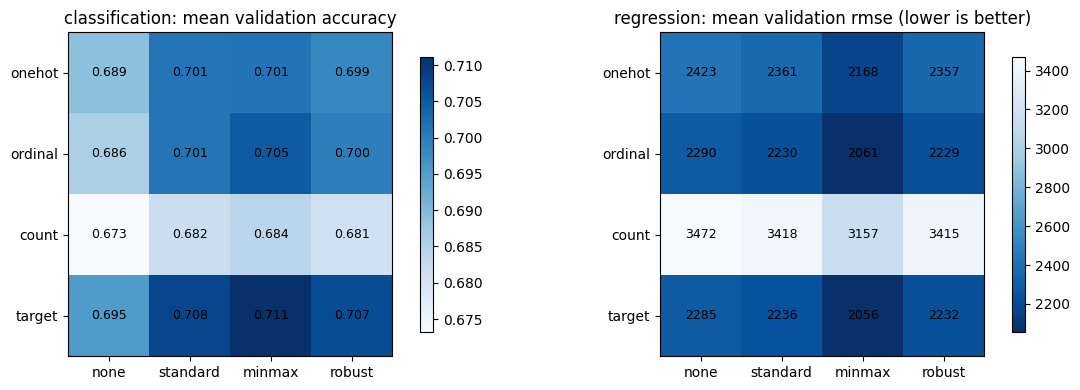

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, task, cmap in zip(axes, ["classification", "regression"], ["Blues", "Blues_r"]):
    metric = config[task]["selection_metric"]
    pivot = grid_rankings[task].pivot(index="encoder", columns="scaler", values=f"mean_{metric}").loc[ENCODERS, SCALERS]
    image = ax.imshow(pivot.values, cmap=cmap)
    ax.set_xticks(range(len(SCALERS)), SCALERS)
    ax.set_yticks(range(len(ENCODERS)), ENCODERS)
    for i in range(len(ENCODERS)):
        for j in range(len(SCALERS)):
            ax.text(j, i, f"{pivot.values[i, j]:.3f}" if metric == "accuracy" else f"{pivot.values[i, j]:.0f}",
                    ha="center", va="center", fontsize=9)
    ax.set_title(f"{task}: mean validation {metric}" + (" (lower is better)" if metric == "rmse" else ""))
    fig.colorbar(image, ax=ax, shrink=0.85)
plt.tight_layout()
plt.show()

**Is the winner really better, or is it the luck of the folds?** Same folds → subtract fold by fold. A mean advantage of more than 2 standard errors is a real edge. Within 2 SE, either pair is defensible, and the choice needs another reason.

In [41]:
pairs_to_check = {
    "classification": [(("target", "minmax"), ("target", "standard")), (("target", "standard"), ("target", "robust")),
                       (("target", "standard"), ("onehot", "robust"))],
    "regression": [(("ordinal", "minmax"), ("target", "minmax")), (("target", "minmax"), ("target", "robust"))],
}
rows = []
for task, pairs in pairs_to_check.items():
    higher_is_better = config[task]["selection_metric"] != "rmse"
    for a, b in pairs:
        result = paired_comparison(grid_scores[task][a], grid_scores[task][b], higher_is_better)
        rows.append({"task": task, "A": " + ".join(a), "B": " + ".join(b), **result})
paired_table = pd.DataFrame(rows)
display(paired_table.round(4))

,task,A,B,mean_advantage,se,folds_a_better,n_folds,decisive
0,classification,target + minmax,target + standard,0.0033,0.0072,2,5,False
1,classification,target + standard,target + robust,0.0010,0.0012,3,5,False
2,classification,target + standard,onehot + robust,0.0093,0.0035,4,5,True
3,regression,ordinal + minmax,target + minmax,-5.8814,4.7305,1,5,False
4,regression,target + minmax,target + robust,176.5703,99.1993,5,5,False


**Decision** (stored in `config.yaml` → `classification.preprocessing` / `regression.preprocessing`). **Rule:** keep the current pair unless another pair is *decisively* better. Switching on noise would make the pipeline change every time the data changes.

- **Classification → target encoding + standard scaling.** `target + minmax` ranks first, but it is tied with `target + standard` (+0.003, SE 0.007), and so is `target + robust`. No pair is decisively better, so the current choice stays. Target encoding is also **decisively** ahead of one-hot (+0.009 vs `onehot + robust`, SE 0.0035, better on 4 of 5 folds) while using one column per feature instead of one per category. Count encoding takes the bottom 4 places: equal counts collide, and frequency says little about repurchase. Scaling matters: `target + none` drops to 0.695.
- **Regression → target encoding + min-max scaling.** It ranks first, and min-max is the best scaler for every encoder. With ridge, the scale decides how strongly each coefficient is penalised, so this is mostly a regularisation effect. `ordinal + minmax` is a tie (6 RMSE worse, SE 5), and ordinal encoding would impose an order on unordered categories (salesperson, transport method, …). `target + minmax` beats `target + robust` by ≈ 177 RMSE on all 5 folds (1.8 SE).

These pairs were chosen with the linear models. In section 10 the tree models use the same recipe; scaling doesn't change their splits.

# <font color='#BFD72F' size=6>**10. Recipe + model = one Pipeline**</font> <a class="anchor" id="pipeline"></a>

`build_pipeline()` (`src/pipeline.py`) puts `build_preprocessor()` and the model into one sklearn `Pipeline`. In every fold, `fit` learns the medians, the target-encoding means, the scaling statistics **and** the model from that fold's training rows only. `predict` then applies all of it unchanged to the validation block.

Candidates (`config.yaml` → `<task>.candidate_models`), each with its task's chosen recipe:

| | Classification | Regression |
|---|---|---|
| floor to beat | `DummyClassifier` (most frequent class) | `DummyRegressor` (mean) |
| linear | logistic regression | ridge |
| single tree | decision tree, depth 5 | decision tree, depth 5 |
| ensemble | random forest, 300 trees, ≥ 5 rows per leaf | random forest, 300 trees, ≥ 5 rows per leaf |

Hyperparameters are untouched defaults or simple limits for now; tuning comes later. **Train** vs **validation** scores show over- and under-fitting.

[Back to TOC](#toc)

In [42]:
model_results, model_fold_scores = {}, {}
for task in ["classification", "regression"]:
    X_dev, _, y_dev, _, _, _ = splits[task]
    recipe = task_preprocessing_config(config, task)
    metric = config[task]["selection_metric"]
    rows, model_fold_scores[task] = {}, {}
    for model_cfg in config[task]["candidate_models"]:
        pipe = build_pipeline(recipe, TASK_MODELS[task].build_model(model_cfg))
        scores = cross_validate_pipeline(pipe, X_dev, y_dev, task_folds[task], SCORING[task])
        rows[model_cfg["type"]] = scores.mean()
        model_fold_scores[task][model_cfg["type"]] = scores[f"validation_{metric}"].to_numpy()
    model_results[task] = pd.DataFrame(rows).T
    print(f"\n{task} ({recipe['encoder']} + {recipe['scaler']}): mean over {len(task_folds[task])} temporal folds")
    display(model_results[task].round(4))


classification (target + standard): mean over 5 temporal folds


,train_accuracy,validation_accuracy,train_f1,validation_f1,train_roc_auc,validation_roc_auc
dummy,0.5532,0.5530,0.7122,0.7117,0.5000,0.5000
logistic_regression,0.7081,0.7078,0.7232,0.7237,0.7757,0.7728
decision_tree,0.7378,0.6515,0.7589,0.6836,0.8034,0.6972
random_forest,0.8504,0.7083,0.8623,0.7429,0.9380,0.7790



regression (target + minmax): mean over 5 temporal folds


,train_rmse,validation_rmse,train_mae,validation_mae,train_r2,validation_r2
dummy,1940.1767,2471.5528,1358.6014,1637.9819,0.0000,-0.0496
ridge,1485.4665,2055.5762,997.4644,1397.0025,0.4141,0.2273
decision_tree,1200.7443,2370.9578,813.1190,1467.9438,0.6189,-0.0194
random_forest,985.1740,1942.4794,588.7954,1275.0570,0.7309,0.3312


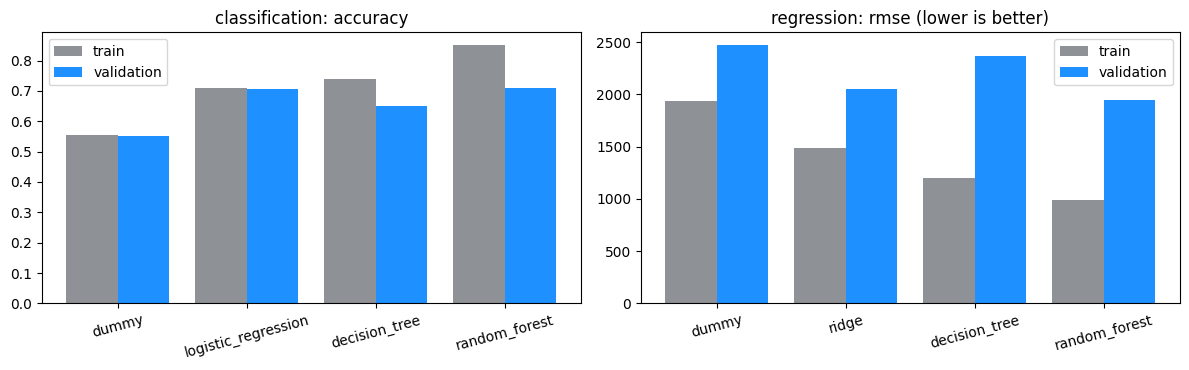

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, task in zip(axes, ["classification", "regression"]):
    metric = config[task]["selection_metric"]
    table = model_results[task][[f"train_{metric}", f"validation_{metric}"]]
    positions = np.arange(len(table))
    ax.bar(positions - 0.2, table[f"train_{metric}"], width=0.4, color="#8E9196", label="train")
    ax.bar(positions + 0.2, table[f"validation_{metric}"], width=0.4, color="dodgerblue", label="validation")
    ax.set_xticks(positions, table.index, rotation=15)
    ax.set_title(f"{task}: {metric}" + (" (lower is better)" if metric == "rmse" else ""))
    ax.legend()
plt.tight_layout()
plt.show()

In [44]:
rows = []
for task, comparisons in {
    "classification": [("logistic_regression", "dummy"), ("logistic_regression", "random_forest")],
    "regression": [("random_forest", "dummy"), ("random_forest", "ridge")],
}.items():
    higher_is_better = config[task]["selection_metric"] != "rmse"
    for a, b in comparisons:
        result = paired_comparison(model_fold_scores[task][a], model_fold_scores[task][b], higher_is_better)
        rows.append({"task": task, "A": a, "B": b, **result})
display(pd.DataFrame(rows).round(4))

,task,A,B,mean_advantage,se,folds_a_better,n_folds,decisive
0,classification,logistic_regression,dummy,0.1548,0.0187,5,5,True
1,classification,logistic_regression,random_forest,-0.0005,0.0035,3,5,False
2,regression,random_forest,dummy,529.0734,113.9682,5,5,True
3,regression,random_forest,ridge,113.0968,73.7393,3,5,False


**Regression target transform.** `spend_next_90d` is strongly right-skewed (median ≈ 1,000 €, a long tail up to ≈ 25,000 €). A common fix is to fit on `log1p(spend)` and transform predictions back (`regression.model.target_transform: log1p`, a `TransformedTargetRegressor`). Is it better here, measured in euros on the same folds?

In [45]:
print(f"skew of spend_next_90d: {splits['regression'][2].skew():.2f}  |  skew of log1p(spend): {np.log1p(splits['regression'][2]).skew():.2f}")

X_dev, _, y_dev, _, _, _ = splits["regression"]
recipe = task_preprocessing_config(config, "regression")
transform_scores, rows = {}, []
for model_cfg in config["regression"]["candidate_models"]:
    if model_cfg["type"] == "dummy":
        continue
    for transform in ["none", "log1p"]:
        model = regression_model.build_model({**model_cfg, "target_transform": transform})
        scores = cross_validate_pipeline(build_pipeline(recipe, model), X_dev, y_dev, task_folds["regression"], SCORING["regression"])
        transform_scores[(model_cfg["type"], transform)] = scores["validation_rmse"].to_numpy()
        rows.append({"model": model_cfg["type"], "target_transform": transform,
                     **scores[["validation_rmse", "validation_mae", "validation_r2"]].mean().to_dict()})
display(pd.DataFrame(rows).round(3))

display(pd.DataFrame([
    {"model": name, "A": "log1p", "B": "none",
     **paired_comparison(transform_scores[(name, "log1p")], transform_scores[(name, "none")], higher_is_better=False)}
    for name in ["ridge", "decision_tree", "random_forest"]
]).round(3))

skew of spend_next_90d: 2.40  |  skew of log1p(spend): -0.59


,model,target_transform,validation_rmse,validation_mae,validation_r2
0,ridge,none,2055.576,1397.002,0.227
1,ridge,log1p,2788.210,1508.874,-0.381
2,decision_tree,none,2370.958,1467.944,-0.019
3,decision_tree,log1p,2474.543,1458.189,-0.087
4,random_forest,none,1942.479,1275.057,0.331
5,random_forest,log1p,2327.040,1348.401,0.045


,model,A,B,mean_advantage,se,folds_a_better,n_folds,decisive
0,ridge,log1p,none,-732.634,325.402,0,5,True
1,decision_tree,log1p,none,-103.585,106.780,2,5,False
2,random_forest,log1p,none,-384.560,62.179,0,5,True


**Verdict: no transform** (`target_transform: none`). The log scale removes the skew, but in RMSE it is decisively worse for ridge (+733) and for the chosen random forest (+385, worse on all 5 folds). For the depth-5 tree, the weakest model, it is also worse, but not decisively (+104 ± 107 RMSE). A model fitted on `log1p(spend)` predicts something close to the *median* spend once transformed back, so it underestimates the large spenders that dominate RMSE. The option stays available in `regression/model.py` for a log-scale metric (e.g. RMSLE).

**Decision** (stored in `config.yaml` → `<task>.model`), with the same rule as section 9:

- **Classification → logistic regression.** It beats the dummy on every fold (0.708 vs 0.553), and train ≈ validation (0.708 / 0.708), so it doesn't overfit. The random forest ties it (0.0005 ahead, SE 0.0035, better on 2 of 5 folds), with slightly better F1/ROC-AUC, but it overfits (train 0.85) and isn't decisively better, so logistic regression stays: simpler, stable, and easy to explain. The single depth-5 tree is clearly worse (0.652).
- **Regression → random forest.** It has the lowest validation RMSE (≈ 1942 vs 2056 for ridge and 2472 for the dummy) and the highest R² (≈ 0.33). Its edge over ridge holds on 3 of 5 folds and is not decisive (≈ 113 RMSE, SE 74). It also overfits clearly (train RMSE ≈ 985), which tuning should address. The single depth-5 tree is barely better than the dummy (R² −0.02 vs −0.05): one tree overfits the extra customer categories. The target is kept in euros (no log transform, see above).

Every chosen model beats its dummy floor on every fold, so the preprocessing produces usable signal for both tasks. These are **development-set** scores. The locked test set is still untouched and is scored once, at the end, for the final models.

In [46]:
final_pipelines = {}
for task in ["classification", "regression"]:
    X_dev, _, y_dev, _, _, _ = splits[task]
    final_pipelines[task] = build_pipeline(
        task_preprocessing_config(config, task), TASK_MODELS[task].build_model(config[task]["model"]),
    ).fit(X_dev, y_dev)                                  # all development rows; locked test still untouched
final_pipelines["classification"]

,steps,"[('prep', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('numeric', ...), ('categorical', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


**Conclusion — section 10.** Preprocessing and model are a single estimator per task, fitted on the development rows only. Both chosen models clearly beat their dummy baselines. The locked test set is still untouched.

# <font color='#BFD72F' size=6>**11. Data additions: consistency rules, new features, customer table, rare categories**</font> <a class="anchor" id="additions"></a>

Each addition is measured the same way: the task's chosen recipe and model are scored **with and without** the addition, on the same temporal folds, and compared fold by fold. An addition is kept when it helps; when it doesn't, the simpler pipeline wins.

[Back to TOC](#toc)

### 11.1 Consistency rules (section 5.2)

In [47]:
no_consistency = copy.deepcopy(config)
no_consistency["diagnostics"]["consistency_rules"] = []

rows = []
for task in ["classification", "regression"]:
    recipe = task_preprocessing_config(config, task)
    metric = config[task]["selection_metric"]
    scores = {}
    for name, cfg in {"with": config, "without": no_consistency}.items():
        data = prepare_task_data(cfg, task)
        assert data["X_dev"].index.equals(splits[task][0].index)       # same rows -> same folds
        pipe = build_pipeline(recipe, TASK_MODELS[task].build_model(config[task]["model"]))
        scores[name] = cross_validate_pipeline(pipe, data["X_dev"], data["y_dev"], task_folds[task], SCORING[task])[f"validation_{metric}"].to_numpy()
    rows.append({"task": task, "metric": metric, "with rules": scores["with"].mean(), "without rules": scores["without"].mean(),
                 **paired_comparison(scores["with"], scores["without"], metric != "rmse")})
display(pd.DataFrame(rows).round(4))

,task,metric,with rules,without rules,mean_advantage,se,folds_a_better,n_folds,decisive
0,classification,accuracy,0.7078,0.7133,-0.0055,0.0023,0,5,True
1,regression,rmse,1942.4794,1937.8509,-4.6286,12.7102,2,5,False


**Verdict: keep the rules.** For regression they make no decisive difference (4.6 ± 12.7 RMSE in favour of the uncorrected values, better on 2 of 5 folds). For classification, fixing the 130 impossible values costs 0.006 accuracy, which is decisive (worse on all 5 folds). We keep them anyway:
- **They carry no repurchase information.** The corrupted rows have the same repurchase rate as everyone else (0.54, 0.56 and 0.53 vs 0.56, section 5.2).
- **The loss most likely comes from scaling.** Values up to 25× too large stretch the scale of three columns for every other row, and logistic regression happens to score slightly better on that distorted scale.
- **Robustness.** A model that depends on impossible values would behave unpredictably on new data, where the corruption could be different or absent.

Correct inputs come first; tuning (later) can recover accuracy honestly.

### 11.2 Purchase-time features

Only information known **at the moment of the purchase** is used (`config.yaml` → `diagnostics.date_features`, `derived_features`):
- **date parts:** `purchase_month`, `purchase_weekday`;
- **ratios of the same row:** `margin` (net − cost), `margin_rate`, `discount_rate` (discounts / gross), `avg_line_value` (net / lines), `spend_share_30d` and `spend_share_90d` (recent spend / 365-day spend).

No feature looks at later purchases or at other rows.

### 11.3 Customer table (`clientes.csv`)

In [48]:
customers = standardize_columns(clientes_raw, {})
customer_profile = pd.DataFrame({"missing_%": customers.isna().mean().mul(100).round(1), "distinct_values": customers.nunique()})
display(customer_profile)
print("training purchases whose customer is not in clientes.csv:", int((~train_rules["customer_id"].isin(customers["customer_id"])).sum()),
      "| test:", int((~test_rules["customer_id"].isin(customers["customer_id"])).sum()))
print("purchases made before the customer's customer_since_year:", int((train_rules["years_as_customer"] < 0).sum()),
      "| test:", int((test_rules["years_as_customer"] < 0).sum()))

,missing_%,distinct_values
customer_id,0.0,1143
country_or_region,0.0,11
commercial_region,10.0,37
island,50.6,10
municipality,13.9,183
city,47.8,417
postal_area,6.2,271
postal_code,14.9,828
street,52.3,511
address,0.5,1120


training purchases whose customer is not in clientes.csv: 0 | test: 0
purchases made before the customer's customer_since_year: 0 | test: 0


Every customer is found, and no purchase is dated before the customer's `customer_since_year`, so the join adds no future information. Columns (`config.yaml` → `customers`):
- **kept:** `country_or_region`, `commercial_region`, `island`, `municipality` (geography at a usable level of detail), plus `customer_since_year`, turned into `years_as_customer` at the moment of the purchase;
- **dropped:**
  - `customer_type` is 100% missing.
  - `company_name` and `address` are unique per customer, so they would act as a customer id.
  - `street` and `city` are about half missing and have hundreds of levels.
  - `postal_code` and `postal_area` have hundreds of levels, and the kept geography already covers them.

The join is a stateless, row-preserving step (`add_customer_features()`), so it also runs on test.csv.

**The full preprocessing of the customer table** is in `notebooks/04_customer_table.ipynb` (`src/customers.py`):
- validation and key checks;
- labels → codes;
- exact recovery of missing regions through the geographic hierarchy;
- `island` as a structural `"none"` outside the island regions;
- the "customer before the records" flag and profile completeness, which the regression now also uses.

The ablation below tests the customer table as introduced here: the four geography columns and `years_as_customer`.

### 11.4 Which additions help? Ablation per task

`original`: the 26 + 6 features of sections 5–10. `all new`: plus every date, ratio and customer feature. Then each group is removed in turn (`original + date + customer` is `all new` without the ratios). Rare-category grouping (`rare_category_min_count`) is tested on top: categories with fewer than N **training** rows (`transport_method` has 80 levels, 40 of them under 10 rows) become `rare`. The threshold is learned inside each fold by `RareCategoryGrouper`.

In [49]:
DATE_FEATURES = [f"purchase_{part}" for part in diag_cfg["date_features"]]
DERIVED_FEATURES = list(diag_cfg["derived_features"])
CUSTOMER_NUMERIC = list(config["customers"]["derived_features"])
# the customer-table geography as added in this section (notebook 04 adds and tests two more customer features)
CUSTOMER_CATEGORICAL = ["country_or_region", "commercial_region", "island", "municipality"]

ablation_tables, ablation_paired = {}, {}
for task in ["classification", "regression"]:
    X_dev, _, y_dev, _, _, _ = splits[task]
    recipe = task_preprocessing_config(config, task)
    original = {**recipe, "numeric_features": prep_cfg["numeric_features"], "categorical_features": prep_cfg["categorical_features"]}

    def with_features(numeric=(), categorical=(), **extra):
        return {**original, "numeric_features": original["numeric_features"] + list(numeric),
                "categorical_features": original["categorical_features"] + list(categorical), **extra}

    all_numeric, all_categorical = DATE_FEATURES + DERIVED_FEATURES + CUSTOMER_NUMERIC, CUSTOMER_CATEGORICAL
    variants = {
        "original": original,
        "all new": with_features(all_numeric, all_categorical),
        "all new - date": with_features(DERIVED_FEATURES + CUSTOMER_NUMERIC, all_categorical),
        "all new - customer": with_features(DATE_FEATURES + DERIVED_FEATURES),
        "original + date + customer": with_features(DATE_FEATURES + CUSTOMER_NUMERIC, CUSTOMER_CATEGORICAL),
        "original + rare >= 10": with_features(rare_category_min_count=10),
        "original + rare >= 30": with_features(rare_category_min_count=30),
    }
    metric = config[task]["selection_metric"]
    table, per_fold = compare_preprocessing_variants(
        variants, lambda: TASK_MODELS[task].build_model(config[task]["model"]), X_dev, y_dev, task_folds[task], SCORING[task], metric)
    ablation_tables[task] = table
    ablation_paired[task] = pd.DataFrame([
        {"A": a, "B": b, **paired_comparison(per_fold[a], per_fold[b], metric != "rmse")}
        for a, b in [("all new", "original"), ("all new", "all new - date"), ("all new", "original + date + customer"),
                     ("all new", "all new - customer"), ("original + date + customer", "original"),
                     ("original + rare >= 10", "original")]
    ])
    print(f"\n{task}: validation {metric}")
    display(table.round(4))
    display(ablation_paired[task].round(4))


classification: validation accuracy


,variant,mean_accuracy,std_accuracy
0,all new - customer,0.7088,0.0137
1,original,0.7078,0.0155
2,all new - date,0.7050,0.0114
3,all new,0.7045,0.0102
4,original + rare >= 30,0.7031,0.0166
5,original + date + customer,0.7023,0.0164
6,original + rare >= 10,0.7004,0.0158


,A,B,mean_advantage,se,folds_a_better,n_folds,decisive
0,all new,original,-0.0033,0.0037,1,5,False
1,all new,all new - date,-0.0005,0.0024,2,5,False
2,all new,original + date + customer,0.0022,0.0033,2,5,False
3,all new,all new - customer,-0.0043,0.0018,0,5,True
4,original + date + customer,original,-0.0055,0.0015,0,5,True
5,original + rare >= 10,original,-0.0074,0.0029,0,5,True



regression: validation rmse


,variant,mean_rmse,std_rmse
0,all new,1939.8483,181.4177
1,original + date + customer,1943.1552,164.5057
2,all new - customer,1983.8296,216.8361
3,all new - date,1987.8906,203.5800
4,original,1994.9212,203.9603
5,original + rare >= 30,1998.8072,207.0372
6,original + rare >= 10,2001.4086,210.8245


,A,B,mean_advantage,se,folds_a_better,n_folds,decisive
0,all new,original,55.0728,45.4760,4,5,False
1,all new,all new - date,48.0423,31.5686,5,5,False
2,all new,original + date + customer,3.3068,12.6043,3,5,False
3,all new,all new - customer,43.9812,33.0332,3,5,False
4,original + date + customer,original,51.7660,37.6706,4,5,False
5,original + rare >= 10,original,-6.4874,3.6305,1,5,False


**Verdict** (stored per task in `config.yaml` → `<task>.preprocessing`):

| Addition | Classification (accuracy) | Regression (RMSE) | Decision |
|---|---|---|---|
| all new features vs original | −0.003 (better on 1/5 folds) | 55 RMSE better (4/5) | per task |
| date parts (`purchase_month`, `purchase_weekday`) | −0.0005 (noise) | **48 RMSE better with them, 5/5 folds** | regression: **kept** |
| customer table | **0.004 better *without*, decisive** | **44 RMSE better with them** | regression: **kept** |
| ratios (margin, discount rate, …) | +0.002 (noise) | 3 RMSE (noise) | not used: no gain, more columns |
| rare-category grouping (≥ 10 / ≥ 30 rows) | −0.007 (decisive) / −0.005 | 6 RMSE worse / 4 RMSE worse (noise) | **off** for both (`rare_category_min_count: 0`) |

- **Classification keeps the original 32 features.** None of the additions helps logistic regression; the customer table, and date + customer together, decisively hurt it.
- **Regression adds the date parts and the customer table** (`extra_numeric_features`, `extra_categorical_features`). Together they lower RMSE by 52, better on 4 of 5 folds, and the date parts help on every fold. Spend seems to depend on season and on where the customer is, while repurchase doesn't. Each gain on its own is under 2 SE, but both have a clear reason and point the same way.
- **Rare categories are not grouped.** The target encoder already shrinks a rare category's mean towards the overall mean, so grouping only throws away information.

The ratio features stay computed in `config.yaml` (`derived_features`) and are one config line away from either task.

# <font color='#BFD72F' size=6>**12. Alternative imputers**</font> <a class="anchor" id="imputers"></a>

Section 6 chose median / most frequent from the missingness mechanism. Is a smarter imputer better? Each option is fitted **inside each fold** (on training rows only), with the task's chosen recipe and model:
- **numeric:** `median` (current), `mean`, `constant` (0), `knn` (5 neighbours, after scaling so large-valued columns don't dominate the distances), `iterative` (each column regressed on the others, also after scaling);
- **categorical:** `most_frequent` vs an explicit `"Missing"` category (`constant`).

[Back to TOC](#toc)

In [50]:
def versus(scores_a, scores_b, higher_is_better):
    r = paired_comparison(scores_a, scores_b, higher_is_better)
    decisive = ", decisive" if r["decisive"] else ""
    return f"{r['mean_advantage']:+.4f} (SE {r['se']:.4f}, better on {r['folds_a_better']}/{r['n_folds']} folds{decisive})"


imputer_tables = {}
for task in ["classification", "regression"]:
    X_dev, _, y_dev, _, _, _ = splits[task]
    recipe = task_preprocessing_config(config, task)
    current = recipe["imputation"]
    variants = {f"numeric {s}": {**recipe, "imputation": {**current, "numeric_strategy": s}}
                for s in ["median", "mean", "constant", "knn", "iterative"]}
    other_categorical = "most_frequent" if current["categorical_strategy"] == "constant" else "constant"
    variants[f"categorical {other_categorical}"] = {**recipe, "imputation": {**current, "categorical_strategy": other_categorical}}
    metric = config[task]["selection_metric"]
    table, per_fold = compare_preprocessing_variants(
        variants, lambda: TASK_MODELS[task].build_model(config[task]["model"]), X_dev, y_dev, task_folds[task], SCORING[task], metric)
    reference = "numeric median"
    table["vs numeric median"] = [
        "" if v == reference else versus(per_fold[v], per_fold[reference], metric != "rmse") for v in table["variant"]
    ]
    imputer_tables[task] = table
    print(f"\n{task} (current: numeric {current['numeric_strategy']}, categorical {current['categorical_strategy']}): validation {metric}")
    display(table.round(4))


classification (current: numeric median, categorical most_frequent): validation accuracy


,variant,mean_accuracy,std_accuracy,vs numeric median
0,numeric iterative,0.7083,0.0153,"+0.0005 (SE 0.0006, better on 2/5 folds)"
1,numeric median,0.7078,0.0155,
2,numeric knn,0.7078,0.0161,"+0.0000 (SE 0.0013, better on 1/5 folds)"
3,categorical constant,0.7076,0.0170,"-0.0002 (SE 0.0010, better on 2/5 folds)"
4,numeric mean,0.7071,0.0174,"-0.0007 (SE 0.0010, better on 1/5 folds)"
5,numeric constant,0.7064,0.0165,"-0.0014 (SE 0.0006, better on 0/5 folds, decis..."



regression (current: numeric median, categorical constant): validation rmse


,variant,mean_rmse,std_rmse,vs numeric median
0,numeric mean,1942.2253,165.9460,"+0.2541 (SE 0.3624, better on 3/5 folds)"
1,numeric median,1942.4794,165.1851,
2,numeric iterative,1943.6122,166.3086,"-1.1328 (SE 0.9388, better on 2/5 folds)"
3,numeric knn,1943.9829,166.7986,"-1.5035 (SE 1.2392, better on 2/5 folds)"
4,numeric constant,1944.4845,166.8078,"-2.0051 (SE 1.5838, better on 0/5 folds)"
5,categorical most_frequent,1944.8946,163.7790,"-2.4152 (SE 1.1066, better on 1/5 folds, decis..."


**Verdict** (same rule: change only for a decisive gain with a sensible reason):
- **Classification:** the median stays. Every alternative is within 0.0014 accuracy of it. `constant` (0) is the only decisive one, and it is decisively **worse** (0 of 5 folds); 0 already means "not applicable" in this pipeline (structural fill, 5.3) anyway.
- **Regression, numeric: the median stays, and the KNN question is closed.** KNN was once decisively better than the median here (6 RMSE, SE 3, all 5 folds). Notebook 05 found why: its neighbours gave a better 365-day spend. The pipeline now estimates that spend from the row itself (365-day purchase count × mean purchase value, notebook 05 section 6). With that estimate, the customer-history fill and the row limits, KNN is 1.5 RMSE **worse** (2 of 5 folds). Notebook 05, section 8 re-tested it with a tuned forest, 3 / 5 / 10 / 20 neighbours and distance weighting: never decisive. Mean, iterative and constant are within 2 RMSE.
- **Regression, categorical:** the explicit **`"Missing"` category** (`categorical_strategy: constant`) stays, now **decisively**: the most frequent value is 2.4 RMSE worse (SE 1.1), and `"Missing"` is better on 4 of 5 folds. The reason for it holds: the remaining customer gaps are incomplete profiles related to the target (section 6), and filling them with the most common region or municipality would hide that.

# <font color='#BFD72F' size=6>**13. From this notebook to the pipeline**</font> <a class="anchor" id="to-pipeline"></a>

| This notebook | Pipeline |
|---|---|
| Section 1, 2.2 | `src/data.py` → `load_data(path, placeholder_tokens)`, `report_placeholders()`, `standardize_columns()`; `config.yaml` → `data`, `diagnostics.placeholder_tokens`, `diagnostics.column_renames` |
| Section 2.10 | `src/data.py` → `validate_schema()`, `standardize_dtypes()`; `config.yaml` → `schema`, `dtypes` |
| Section 4.4 | `src/data.py` → `validate_customer_ids()` |
| Sections 2.2, 5.1–5.4, 11.3 | `src/cleaning.py` → `prepare_table()` = `validate_schema()` + `clean_dataset()` (`flag_invalid_values`, `apply_consistency_rules`, `apply_recompute_rules`, `apply_structural_fill`, `add_flags`, `add_date_features`, `add_derived_features`, redundant columns) + `add_customer_features()` + `standardize_dtypes()`; `config.yaml` → `diagnostics`, `customers` |
| Sections 2.1, 2.4, 4 | `src/cleaning.py` → `drop_training_rows()`: training file only, before the split |
| Sections 2.6–2.7 | `regression/preprocessing.py` → `select_training_rows()` (`config.yaml` → `regression.row_filter`) |
| Section 6 | `config.yaml` → `preprocessing.imputation`, `mnar_indicator_sources` |
| Section 7 | `src/preprocessing.py` → `split_features_target()`, `split_dev_test()`; `src/pipeline.py` → `prepare_task_data()`; `config.yaml` → `data`, `test_set` |
| Section 8 | `src/preprocessing.py` → `check_feature_lists()`, `build_preprocessor()` (with the `MissingIndicator` step); `src/pipeline.py` → `build_pipeline()`, `save_pipeline()`, `load_pipeline()`, `predict_new_records()`; `tests/test_pipeline.py` |
| Section 9 | `src/evaluate.py` → `temporal_folds()`, `compare_encoders_scalers()`, `paired_comparison()`; `config.yaml` → `cv`, `<task>.comparison_model`, `<task>.preprocessing` |
| Section 10 | `src/evaluate.py` → `cross_validate_pipeline()`; `<task>/model.py` → `build_model()` (regression: `target_transform`); `<task>/evaluate.py` → `SCORING`, reports; `config.yaml` → `<task>.metrics`, `<task>.selection_metric`, `<task>.candidate_models`, `<task>.model` |
| Section 11 | `src/evaluate.py` → `compare_preprocessing_variants()`; `src/preprocessing.py` → `RareCategoryGrouper`; `config.yaml` → `<task>.preprocessing.extra_*_features`, `preprocessing.rare_category_min_count` |
| Section 12 | `src/preprocessing.py` → imputers (`median`, `mean`, `constant`, `knn`, `iterative`); `config.yaml` → `<task>.preprocessing.imputation` |
| Everything | `python main.py`: validation, cleaning, temporal CV against the dummy floor, optional Optuna tuning with nested CV (`src/tuning.py`, `<task>.tuning`), refit, scoreboard and report (`src/results.py`, `results/`), saved model (`models/`) and test.csv predictions (`results/predictions/`) |

[Back to TOC](#toc)